# ***Student Stress Level Classification Using Zero-Order Sugeno Fuzzy Inference System***
Mata Kuliah: Komputasi Lunak
<br>Kelas: D
<br>Kelompok: 6

Anggota Kelompok:
1. Puti Shasta Khafiyani (24060124140132)
2. Anggita Kirana Puspa (24060124130064)
3. Varissa Nabila Kifli (24060124140125)
---
Tingkat stres mahasiswa dipengaruhi oleh berbagai faktor, di antaranya durasi tidur dan waktu belajar. Kedua faktor tersebut tidak selalu memiliki hubungan yang tegas dengan tingkat stres karena setiap mahasiswa dapat berada pada tingkat keanggotaan yang berbeda dalam suatu kategori. Oleh karena itu, diperlukan pendekatan yang mampu menangani ketidakpastian dalam proses klasifikasi.

Proyek ini menerapkan Zero-Order Sugeno Fuzzy Inference System untuk mengklasifikasikan tingkat stres mahasiswa berdasarkan variabel Sleep Hours dan Study Hours. Model dirancang menggunakan fungsi keanggotaan Trapezoidal, sembilan aturan fuzzy, serta nilai konsekuen 15, 50, dan 85 yang merepresentasikan kategori Low, Moderate, dan High. Parameter awal fungsi keanggotaan ditentukan dari distribusi data sub-training (kuantil), kemudian dioptimalkan menggunakan Differential Evolution (DE) dengan data validation sebagai fungsi fitness (macro F1-Score); data testing hanya dipakai untuk evaluasi akhir. Proses inferensi menggunakan operator MIN dan metode Weighted Average untuk menghasilkan skor akhir. Evaluasi model dilakukan pada data sub-training, validation, dan testing menggunakan metrik Accuracy, Precision, Recall, F1-Score, serta Confusion Matrix.

# 1. Setup & Configuration  

In [1]:
# ============================================================
# TAHAP 0: SETUP & KONFIGURASI
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ---------- Data ----------
import os, glob
DIR_DATA = "/kaggle/input/datasets/steve1215rogg/student-lifestyle-dataset"

# Cari file CSV di folder dataset (nama file tidak perlu ditebak)
PATH = None
if os.path.isdir(DIR_DATA):
    _csv = sorted(glob.glob(os.path.join(DIR_DATA, "*.csv")))
    if _csv:
        PATH = _csv[0]

# Fallback bila notebook dijalankan di luar Kaggle (laptop / Colab / lokal)
if PATH is None:
    for _p in ["student_lifestyle_dataset.csv",
               "/mnt/user-data/uploads/student_lifestyle_dataset.csv"]:
        if os.path.exists(_p):
            PATH = _p
            break

assert PATH is not None, f"File CSV tidak ditemukan di {DIR_DATA}"
print("Dataset dipakai:", PATH)

COL_TIDUR   = "Sleep_Hours_Per_Day"
COL_BELAJAR = "Study_Hours_Per_Day"
COL_LABEL   = "Stress_Level"

# ---------- Label & skor (konsekuen Sugeno) ----------
KELAS = ["Low", "Moderate", "High"]            # urutan tetap untuk laporan & confusion matrix
SKOR_KELAS = {"Low": 15, "Moderate": 50, "High": 85}
PERSENTIL =  [0, 0.25, 0.50, 0.75, 1.0]         # hanya untuk EDA

# ---------- Himpunan fuzzy  ----------
HIMP_TIDUR   = ["Kurang", "Cukup", "Banyak"]
HIMP_BELAJAR = ["Sedikit", "Sedang", "Banyak"]
LEBAR_TRANSISI = {"tidur": 0.5, "belajar": 0.5}   # setengah lebar zona transisi (jam) di tiap batas
BATAS_TIDUR_ATAS = 8.0

# ---------- Inferensi ----------
OPERATOR_AND = min                              # bisa diganti hasil kali (product)
SKOR_DEFAULT = 50                               # fallback bila total alpha = 0

# ---------- Split & reproduktibilitas ----------
SEED = 42
TEST_SIZE = 0.30

# ---------- Tampilan ----------
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
sns.set_style("whitegrid")
np.random.seed(SEED)

def cek_konfigurasi(df):
    wajib = [COL_TIDUR, COL_BELAJAR, COL_LABEL]
    hilang = [c for c in wajib if c not in df.columns]
    assert not hilang, f"Kolom tidak ditemukan: {hilang}. Kolom tersedia: {df.columns.tolist()}"
    label_data = set(df[COL_LABEL].dropna().unique())
    tak_dikenal = label_data - set(KELAS)
    assert not tak_dikenal, f"Label tidak ada di KELAS: {tak_dikenal}"
    print("Konfigurasi OK.")
    print(f"Jumlah baris : {len(df)}")
    print(f"Distribusi   :\n{df[COL_LABEL].value_counts(normalize=True).round(3)}")

Dataset dipakai: /kaggle/input/datasets/steve1215rogg/student-lifestyle-dataset/student_lifestyle_dataset.csv


In [2]:
# ============================================================
# TAHAP 1: LOAD & CEK DATA
# ============================================================
df = pd.read_csv(PATH)

print("Bentuk data :", df.shape)
print("\nKolom       :", df.columns.tolist())
print("\nTipe data   :")
print(df.dtypes)

print("\n5 baris pertama:")
display(df.head())

# Cek konfigurasi (kolom & label)
cek_konfigurasi(df)

# Missing value & duplikat
print("\nMissing value per kolom:")
print(df.isna().sum())
print("\nBaris duplikat      :", df.duplicated().sum())

# Rentang nilai input (cek apakah masuk akal)
print("\nRingkasan input:")
display(df[[COL_TIDUR, COL_BELAJAR]].describe().T)

# Cek nilai tidak wajar (tidur/belajar di luar 0-24 jam)
tak_wajar = df[(df[COL_TIDUR] < 0) | (df[COL_TIDUR] > 24) |
               (df[COL_BELAJAR] < 0) | (df[COL_BELAJAR] > 24)]
print("\nBaris dengan jam tidak wajar:", len(tak_wajar))

Bentuk data : (2000, 8)

Kolom       : ['Student_ID', 'Study_Hours_Per_Day', 'Extracurricular_Hours_Per_Day', 'Sleep_Hours_Per_Day', 'Social_Hours_Per_Day', 'Physical_Activity_Hours_Per_Day', 'GPA', 'Stress_Level']

Tipe data   :
Student_ID                           int64
Study_Hours_Per_Day                float64
Extracurricular_Hours_Per_Day      float64
Sleep_Hours_Per_Day                float64
Social_Hours_Per_Day               float64
Physical_Activity_Hours_Per_Day    float64
GPA                                float64
Stress_Level                        object
dtype: object

5 baris pertama:


,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
0,1,6.9,3.8,8.7,2.8,1.8,2.99,Moderate
1,2,5.3,3.5,8.0,4.2,3.0,2.75,Low
2,3,5.1,3.9,9.2,1.2,4.6,2.67,Low
3,4,6.5,2.1,7.2,1.7,6.5,2.88,Moderate
4,5,8.1,0.6,6.5,2.2,6.6,3.51,High


Konfigurasi OK.
Jumlah baris : 2000
Distribusi   :
Stress_Level
High        0.514
Moderate    0.337
Low         0.148
Name: proportion, dtype: float64

Missing value per kolom:
Student_ID                         0
Study_Hours_Per_Day                0
Extracurricular_Hours_Per_Day      0
Sleep_Hours_Per_Day                0
Social_Hours_Per_Day               0
Physical_Activity_Hours_Per_Day    0
GPA                                0
Stress_Level                       0
dtype: int64

Baris duplikat      : 0

Ringkasan input:


,count,mean,std,min,25%,50%,75%,max
Sleep_Hours_Per_Day,2000.0,7.50125,1.460949,5.0,6.2,7.5,8.8,10.0
Study_Hours_Per_Day,2000.0,7.47580,1.423888,5.0,6.3,7.4,8.7,10.0



Baris dengan jam tidak wajar: 0


# 2. EDA

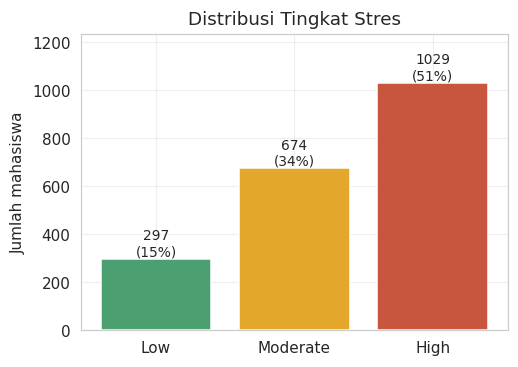

Statistik per kelas stres:


Sleep_Hours_Per_Day                                \
                           count  mean   std  min median   max   
Stress_Level                                                     
Low                          297  8.06  1.21  6.0    8.0  10.0   
Moderate                     674  7.95  1.17  6.0    7.9  10.0   
High                        1029  7.05  1.55  5.0    6.8  10.0   

             Study_Hours_Per_Day                                
                           count  mean   std  min median   max  
Stress_Level                                                    
Low                          297  5.47  0.28  5.0    5.5   5.9  
Moderate                     674  6.97  0.60  6.0    7.0   8.0  
High                        1029  8.39  1.24  5.0    8.7  10.0

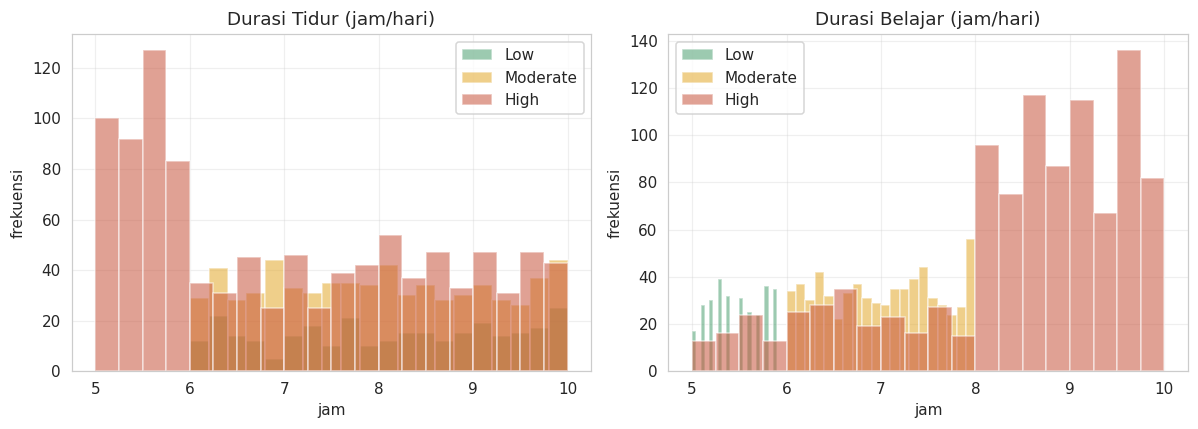

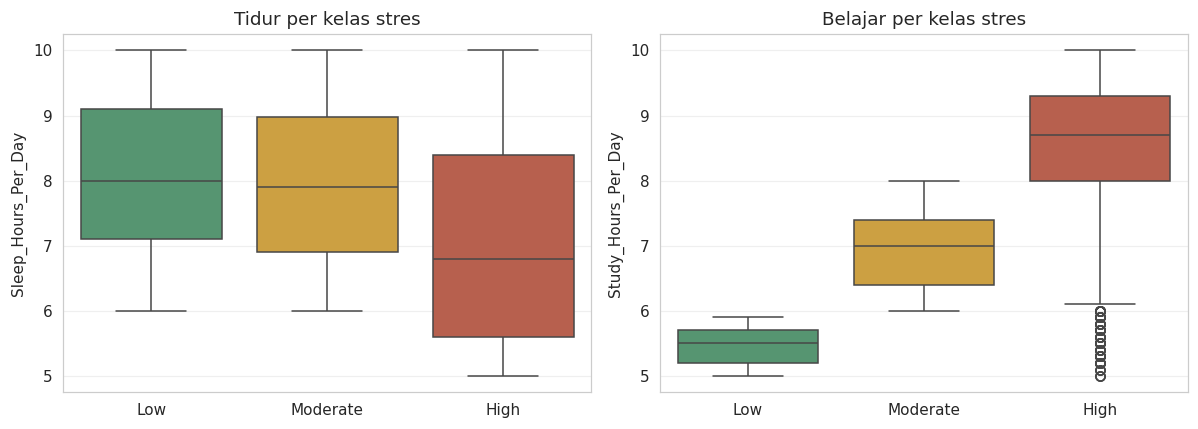

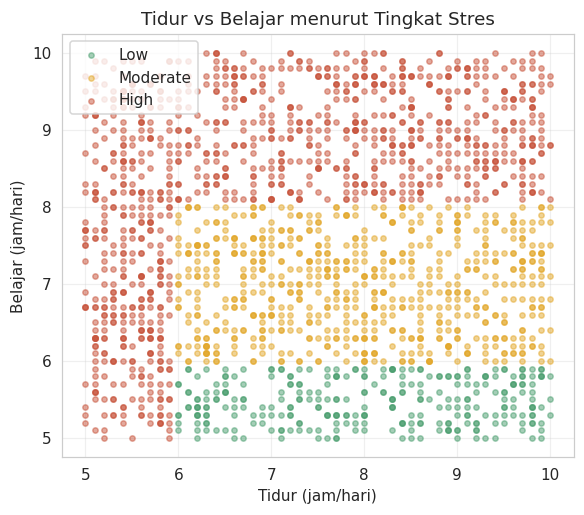

Persentil seluruh data (hanya untuk melihat gambaran; himpunan nanti dari TRAIN):


,Sleep_Hours_Per_Day,Study_Hours_Per_Day
0.00,5.0,5.0
0.25,6.2,6.3
0.50,7.5,7.4
0.75,8.8,8.7
1.00,10.0,10.0


Korelasi dengan skor stres (Low=15, Moderate=50, High=85):
Sleep_Hours_Per_Day   -0.299
Study_Hours_Per_Day    0.739
dtype: float64


In [3]:
# ============================================================
# TAHAP 2: EDA
# ============================================================
warna = {"Low": "#4C9F70", "Moderate": "#E3A82B", "High": "#C8553D"}

# --- 2.1 Distribusi kelas ---
fig, ax = plt.subplots(figsize=(5, 3.5))
hitung = df[COL_LABEL].value_counts().reindex(KELAS)
ax.bar(hitung.index, hitung.values, color=[warna[k] for k in hitung.index])
for i, v in enumerate(hitung.values):
    ax.text(i, v, f"{v}\n({v/len(df):.0%})", ha="center", va="bottom", fontsize=9)
ax.set_title("Distribusi Tingkat Stres")
ax.set_ylabel("Jumlah mahasiswa")
ax.set_ylim(0, hitung.max() * 1.2)
plt.show()

# --- 2.2 Statistik input per kelas ---
print("Statistik per kelas stres:")
ringkas = (df.groupby(COL_LABEL)[[COL_TIDUR, COL_BELAJAR]]
             .agg(["count", "mean", "std", "min", "median", "max"])
             .reindex(KELAS).round(2))
display(ringkas)

# --- 2.3 Histogram input per kelas ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kol, judul in zip(axes, [COL_TIDUR, COL_BELAJAR],
                          ["Durasi Tidur (jam/hari)", "Durasi Belajar (jam/hari)"]):
    for k in KELAS:
        ax.hist(df.loc[df[COL_LABEL] == k, kol], bins=20, alpha=0.55,
                label=k, color=warna[k])
    ax.set_title(judul)
    ax.set_xlabel("jam")
    ax.set_ylabel("frekuensi")
    ax.legend()
plt.tight_layout()
plt.show()

# --- 2.4 Boxplot input per kelas ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kol, judul in zip(axes, [COL_TIDUR, COL_BELAJAR],
                          ["Tidur per kelas stres", "Belajar per kelas stres"]):
    sns.boxplot(data=df, x=COL_LABEL, y=kol, order=KELAS,
            hue=COL_LABEL, hue_order=KELAS,
            palette=warna, legend=False, ax=ax)
    ax.set_title(judul)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

# --- 2.5 Sebaran tidur vs belajar (scatter) ---
fig, ax = plt.subplots(figsize=(6, 5))
for k in KELAS:
    sub = df[df[COL_LABEL] == k]
    ax.scatter(sub[COL_TIDUR], sub[COL_BELAJAR], s=12, alpha=0.5,
               label=k, color=warna[k])
ax.set_xlabel("Tidur (jam/hari)")
ax.set_ylabel("Belajar (jam/hari)")
ax.set_title("Tidur vs Belajar menurut Tingkat Stres")
ax.legend()
plt.show()

# --- 2.6 Persentil input (calon titik himpunan fuzzy, tahap 4) ---
print("Persentil seluruh data (hanya untuk melihat gambaran; himpunan nanti dari TRAIN):")
display(df[[COL_TIDUR, COL_BELAJAR]].quantile(PERSENTIL).round(2))

# --- 2.7 Korelasi ---
peta = df[COL_LABEL].map(SKOR_KELAS)
print("Korelasi dengan skor stres (Low=15, Moderate=50, High=85):")
print(df[[COL_TIDUR, COL_BELAJAR]].corrwith(peta).round(3))

# 3. Preprocessing

In [4]:
# ============================================================
# TAHAP 3A: PREPROCESSING 1 (PEMBERSIHAN, SEBELUM SPLIT)
# Tidak ada statistik yang dihitung dari data di sini.
# ============================================================
print("Bentuk awal:", df.shape)

# 1) Hapus duplikat pada data mentah (kolom ID masih ada, jadi
#    yang terhapus hanya baris yang benar-benar kembar)
n_dup = df.duplicated().sum()
bersih = df.drop_duplicates().copy()
print(f"Duplikat dibuang: {n_dup}")

# 2) Ambil hanya kolom yang dipakai
bersih = bersih[[COL_TIDUR, COL_BELAJAR, COL_LABEL]].copy()

# 3) Rapikan label (spasi / huruf besar-kecil)
bersih[COL_LABEL] = bersih[COL_LABEL].astype(str).str.strip().str.capitalize()

# 4) Pastikan input bertipe numerik
for kol in [COL_TIDUR, COL_BELAJAR]:
    bersih[kol] = pd.to_numeric(bersih[kol], errors="coerce")

# 5) Tangani missing value (di sini: buang barisnya)
print("\nMissing value per kolom:")
print(bersih.isna().sum())
n_sebelum = len(bersih)
bersih = bersih.dropna().reset_index(drop=True)
print(f"Baris dibuang karena missing: {n_sebelum - len(bersih)}")

# 6) Validasi label: hanya boleh Low / Moderate / High
tak_dikenal = set(bersih[COL_LABEL].unique()) - set(KELAS)
assert not tak_dikenal, f"Label tak dikenal: {tak_dikenal}"

# 7) Validasi rentang jam (0-24). Outlier TIDAK dibuang.
salah = bersih[(bersih[COL_TIDUR] < 0) | (bersih[COL_TIDUR] > 24) |
               (bersih[COL_BELAJAR] < 0) | (bersih[COL_BELAJAR] > 24)]
print(f"Baris dengan jam tidak wajar: {len(salah)}")
bersih = bersih.drop(salah.index).reset_index(drop=True)

# 8) Ordinal encoding label -> skor (aturan tetap, bukan hasil belajar)
bersih["skor_label"] = bersih[COL_LABEL].map(SKOR_KELAS)
assert bersih["skor_label"].notna().all()

# 9) Ringkasan hasil
print(f"\nBentuk akhir: {bersih.shape}")
print(bersih.dtypes)
display(bersih.head())
display(bersih[COL_LABEL].value_counts().reindex(KELAS))

Bentuk awal: (2000, 8)
Duplikat dibuang: 0

Missing value per kolom:
Sleep_Hours_Per_Day    0
Study_Hours_Per_Day    0
Stress_Level           0
dtype: int64
Baris dibuang karena missing: 0
Baris dengan jam tidak wajar: 0

Bentuk akhir: (2000, 4)
Sleep_Hours_Per_Day    float64
Study_Hours_Per_Day    float64
Stress_Level            object
skor_label               int64
dtype: object


,Sleep_Hours_Per_Day,Study_Hours_Per_Day,Stress_Level,skor_label
0,8.7,6.9,Moderate,50
1,8.0,5.3,Low,15
2,9.2,5.1,Low,15
3,7.2,6.5,Moderate,50
4,6.5,8.1,High,85


Stress_Level
Low          297
Moderate     674
High        1029
Name: count, dtype: int64

In [5]:
# ============================================================
# TAHAP 3B: SPLIT TRAIN / TEST
# ============================================================
train, test = train_test_split(
    bersih, test_size=TEST_SIZE, random_state=SEED, stratify=bersih[COL_LABEL]
)
train = train.reset_index(drop=True)
test  = test.reset_index(drop=True)

print(f"Train: {len(train)} | Test: {len(test)} | Total: {len(train)+len(test)}")
display(pd.DataFrame({
    "train": train[COL_LABEL].value_counts(normalize=True),
    "test":  test[COL_LABEL].value_counts(normalize=True),
}).reindex(KELAS).round(3))

Train: 1400 | Test: 600 | Total: 2000


,train,test
Stress_Level,,
Low,0.149,0.148
Moderate,0.337,0.337
High,0.514,0.515


# 4. Persiapan Data dan Optimasi

In [6]:

# ============================================================
# TAHAP 4: PERSIAPAN DATA DAN PARAMETER AWAL OPTIMASI DE
# ============================================================

from scipy.optimize import differential_evolution
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# 4.1 Pembagian Data Training dan Validation
# ------------------------------------------------------------

train_fit, validation = train_test_split(
    train,
    test_size=0.20,
    random_state=42,
    stratify=train[COL_LABEL]
)

train_fit = train_fit.reset_index(drop=True)
validation = validation.reset_index(drop=True)

print("PEMBAGIAN DATA OPTIMASI")
print("Sub-training :", len(train_fit))
print("Validation   :", len(validation))
print("Testing      :", len(test))


# ------------------------------------------------------------
# 4.2 Pembentukan Membership Function Baseline
# ------------------------------------------------------------

def bentuk_mf_baseline(data):

    t_min = float(data[COL_TIDUR].min())
    t_max = float(data[COL_TIDUR].max())

    b_min = float(data[COL_BELAJAR].min())
    b_max = float(data[COL_BELAJAR].max())

    s1, s2 = data[COL_TIDUR].quantile([1/3, 2/3])
    b1, b2 = data[COL_BELAJAR].quantile([1/3, 2/3])

    wt = (s2 - s1) / 4
    wb = (b2 - b1) / 4

    return {
        "tidur": {
            "Kurang": (t_min, t_min, s1-wt, s1+wt),
            "Cukup":  (s1-wt, s1+wt, s2-wt, s2+wt),
            "Banyak": (s2-wt, s2+wt, t_max, t_max)
        },
        "belajar": {
            "Sedikit": (b_min, b_min, b1-wb, b1+wb),
            "Sedang":  (b1-wb, b1+wb, b2-wb, b2+wb),
            "Banyak":  (b2-wb, b2+wb, b_max, b_max)
        }
    }


HIMPUNAN_SUGENO = bentuk_mf_baseline(train_fit)

print("\nMEMBERSHIP FUNCTION BASELINE")

for variabel, himpunan in HIMPUNAN_SUGENO.items():
    print(f"\n{variabel.upper()}")

    for nama, parameter in himpunan.items():
        print(
            f"{nama:<10}: "
            f"{tuple(round(float(x), 4) for x in parameter)}"
        )


# ------------------------------------------------------------
# 4.3 Menentukan Batas Domain Input
# ------------------------------------------------------------

BATAS_DOMAIN = {
    "tidur": (
        float(train_fit[COL_TIDUR].min()),
        float(train_fit[COL_TIDUR].max())
    ),
    "belajar": (
        float(train_fit[COL_BELAJAR].min()),
        float(train_fit[COL_BELAJAR].max())
    )
}


# ------------------------------------------------------------
# 4.4 Mengambil Parameter MF Awal
# ------------------------------------------------------------

THETA_AWAL = np.array([
    HIMPUNAN_SUGENO["tidur"]["Kurang"][2],
    HIMPUNAN_SUGENO["tidur"]["Kurang"][3],
    HIMPUNAN_SUGENO["tidur"]["Cukup"][2],
    HIMPUNAN_SUGENO["tidur"]["Cukup"][3],

    HIMPUNAN_SUGENO["belajar"]["Sedikit"][2],
    HIMPUNAN_SUGENO["belajar"]["Sedikit"][3],
    HIMPUNAN_SUGENO["belajar"]["Sedang"][2],
    HIMPUNAN_SUGENO["belajar"]["Sedang"][3]
], dtype=float)

print("\nPARAMETER MF AWAL")
print(np.round(THETA_AWAL, 4))


# ------------------------------------------------------------
# 4.5 Parameter Optimasi Differential Evolution
# ------------------------------------------------------------

MIN_GAP = 0.15
LAMBDA_REG = 0.02

BOUNDS_V3 = []

for nilai, variabel in zip(
    THETA_AWAL,
    ["tidur"] * 4 + ["belajar"] * 4
):
    L, U = BATAS_DOMAIN[variabel]

    BOUNDS_V3.append((
        max(L, nilai - 0.75),
        min(U, nilai + 0.75)
    ))


print("\nBATAS PARAMETER OPTIMASI DE")

for i, bound in enumerate(BOUNDS_V3):
    print(
        f"Parameter {i+1}: "
        f"({float(bound[0]):.4f}, {float(bound[1]):.4f})"
    )

print("\nMIN_GAP    :", MIN_GAP)
print("LAMBDA_REG :", LAMBDA_REG)

print("\nBATAS DOMAIN")
print(BATAS_DOMAIN)


PEMBAGIAN DATA OPTIMASI
Sub-training : 1120
Validation   : 280
Testing      : 600

MEMBERSHIP FUNCTION BASELINE

TIDUR
Kurang    : (5.0, 5.0, 6.175, 7.025)
Cukup     : (6.175, 7.025, 7.875, 8.725)
Banyak    : (7.875, 8.725, 10.0, 10.0)

BELAJAR
Sedikit   : (5.0, 5.0, 6.175, 7.025)
Sedang    : (6.175, 7.025, 7.875, 8.725)
Banyak    : (7.875, 8.725, 10.0, 10.0)

PARAMETER MF AWAL
[6.175 7.025 7.875 8.725 6.175 7.025 7.875 8.725]

BATAS PARAMETER OPTIMASI DE
Parameter 1: (5.4250, 6.9250)
Parameter 2: (6.2750, 7.7750)
Parameter 3: (7.1250, 8.6250)
Parameter 4: (7.9750, 9.4750)
Parameter 5: (5.4250, 6.9250)
Parameter 6: (6.2750, 7.7750)
Parameter 7: (7.1250, 8.6250)
Parameter 8: (7.9750, 9.4750)

MIN_GAP    : 0.15
LAMBDA_REG : 0.02

BATAS DOMAIN
{'tidur': (5.0, 10.0), 'belajar': (5.0, 10.0)}


## 4.6 Verifikasi Pembagian Data
Memastikan pembagian data sesuai rancangan: **Sub-training 1.120** (membentuk MF baseline), **Validation 280** (fitness DE), dan **Testing 600** (evaluasi akhir).

In [7]:
# ============================================================
# TAHAP 4.6: VERIFIKASI PEMBAGIAN DATA
# ============================================================
UKURAN_SEHARUSNYA = {"Sub-training": 1120, "Validation": 280, "Testing": 600}
UKURAN_AKTUAL     = {"Sub-training": len(train_fit),
                     "Validation":   len(validation),
                     "Testing":      len(test)}

ringkas_split = pd.DataFrame({
    "Seharusnya": UKURAN_SEHARUSNYA,
    "Aktual":     UKURAN_AKTUAL,
})
ringkas_split["Sesuai"]    = ringkas_split["Seharusnya"] == ringkas_split["Aktual"]
ringkas_split["Kegunaan"]  = ["MF baseline", "Fitness DE", "Evaluasi akhir"]
display(ringkas_split)

assert ringkas_split["Sesuai"].all(), "Ukuran pembagian data tidak sesuai rancangan"
assert sum(UKURAN_AKTUAL.values()) == len(bersih) == 2000

# Ketiga bagian harus menyusun ulang data bersih tepat satu kali (tidak ada baris hilang / ganda)
kolom_cek = [COL_TIDUR, COL_BELAJAR, COL_LABEL]
gabung    = (pd.concat([train_fit, validation, test])[kolom_cek]
               .sort_values(kolom_cek).reset_index(drop=True))
asli      = bersih[kolom_cek].sort_values(kolom_cek).reset_index(drop=True)
assert gabung.equals(asli), "Gabungan train_fit + validation + test tidak sama dengan data bersih"

# Proporsi kelas tiap bagian (stratified)
display(pd.DataFrame({
    "Sub-training": train_fit[COL_LABEL].value_counts(normalize=True),
    "Validation":   validation[COL_LABEL].value_counts(normalize=True),
    "Testing":      test[COL_LABEL].value_counts(normalize=True),
}).reindex(KELAS).round(3))
print("Verifikasi pembagian data: OK")

,Seharusnya,Aktual,Sesuai,Kegunaan
Sub-training,1120,1120,True,MF baseline
Validation,280,280,True,Fitness DE
Testing,600,600,True,Evaluasi akhir


,Sub-training,Validation,Testing
Stress_Level,,,
Low,0.148,0.150,0.148
Moderate,0.338,0.336,0.337
High,0.514,0.514,0.515


Verifikasi pembagian data: OK


# 5. Pembentukan Membership Function

In [8]:
# ============================================================
# VERSION 3 - TAHAP 2: PEMBENTUKAN MEMBERSHIP FUNCTION
# ============================================================

def bentuk_mf_optimasi(theta):

    s1, s2, s3, s4, b1, b2, b3, b4 = theta

    Ls, Us = BATAS_DOMAIN["tidur"]
    Lb, Ub = BATAS_DOMAIN["belajar"]

    return {
        "tidur": {
            "Kurang": (Ls, Ls, s1, s2),
            "Cukup":  (s1, s2, s3, s4),
            "Banyak": (s3, s4, Us, Us)
        },
        "belajar": {
            "Sedikit": (Lb, Lb, b1, b2),
            "Sedang":  (b1, b2, b3, b4),
            "Banyak":  (b3, b4, Ub, Ub)
        }
    }


# Memastikan parameter awal dapat membentuk enam MF
MF_AWAL_V3 = bentuk_mf_optimasi(THETA_AWAL)

print("MEMBERSHIP FUNCTION AWAL VERSION 3")

for variabel, himpunan in MF_AWAL_V3.items():
    print(f"\n{variabel.upper()}")

    for nama, parameter in himpunan.items():
        parameter_rapi = tuple(
            float(x) for x in parameter
        )

        print(f"{nama:<10}: {parameter_rapi}")

MEMBERSHIP FUNCTION AWAL VERSION 3

TIDUR
Kurang    : (5.0, 5.0, 6.174999999999999, 7.025)
Cukup     : (6.174999999999999, 7.025, 7.875, 8.725000000000001)
Banyak    : (7.875, 8.725000000000001, 10.0, 10.0)

BELAJAR
Sedikit   : (5.0, 5.0, 6.174999999999999, 7.025)
Sedang    : (6.174999999999999, 7.025, 7.875, 8.725000000000001)
Banyak    : (7.875, 8.725000000000001, 10.0, 10.0)


# 6. Rule Base dan Konsekuen

In [9]:

# ============================================================
# TAHAP 6A: DEFINISI RULE BASE DAN KONSEKUEN SUGENO
# ============================================================

KONSEKUEN = {
    "Low": 15,
    "Moderate": 50,
    "High": 85
}

RULE_BASE = [
    (1, "Sedikit", "Kurang", "High"),
    (2, "Sedikit", "Cukup",  "Low"),
    (3, "Sedikit", "Banyak", "Low"),
    (4, "Sedang",  "Kurang", "High"),
    (5, "Sedang",  "Cukup",  "Moderate"),
    (6, "Sedang",  "Banyak", "Moderate"),
    (7, "Banyak",  "Kurang", "High"),
    (8, "Banyak",  "Cukup",  "High"),
    (9, "Banyak",  "Banyak", "High"),
]

def klasifikasi_output(z):
    if z <= 32.5:
        return "Low"
    elif z <= 67.5:
        return "Moderate"
    return "High"

print("Rule Base dan Konsekuen berhasil didefinisikan.")


Rule Base dan Konsekuen berhasil didefinisikan.


In [10]:

# ============================================================
# TAHAP 6B: TABEL RULE BASE
# ============================================================

df_rules = pd.DataFrame(
    RULE_BASE,
    columns=[
        "No.",
        "Study Hours (Belajar)",
        "Sleep Hours (Tidur)",
        "Output"
    ]
)

df_rules["Konsekuen (zᵢ)"] = (
    df_rules["Output"].map(KONSEKUEN)
)

df_rules.index = df_rules["No."].apply(
    lambda x: f"R{x}"
)

df_rules = df_rules.drop(columns=["No."])

print("TABEL RULE BASE — FUZZY SUGENO ORDE NOL")
print("Operator AND = MIN | Konsekuen = Konstanta")
print("=" * 65)

display(df_rules)


TABEL RULE BASE — FUZZY SUGENO ORDE NOL
Operator AND = MIN | Konsekuen = Konstanta


,Study Hours (Belajar),Sleep Hours (Tidur),Output,Konsekuen (zᵢ)
No.,,,,
R1,Sedikit,Kurang,High,85
R2,Sedikit,Cukup,Low,15
R3,Sedikit,Banyak,Low,15
R4,Sedang,Kurang,High,85
R5,Sedang,Cukup,Moderate,50
R6,Sedang,Banyak,Moderate,50
R7,Banyak,Kurang,High,85
R8,Banyak,Cukup,High,85
R9,Banyak,Banyak,High,85


# 7. Fungsi Prediksi Awal

In [11]:
# ============================================================
# VERSION 3 - TAHAP 3: FUNGSI PREDIKSI
# ============================================================

def trapmf(x, a, b, c, d):
    # Versi skalar; memakai trapmf_vec yang didefinisikan pada Tahap 8
    return float(trapmf_vec(np.array([x], dtype=float), (a, b, c, d))[0])


def prediksi_sugeno_v3(df_input, theta):

    mf = bentuk_mf_optimasi(theta)

    z_hasil = []
    kelas_hasil = []

    for _, row in df_input.iterrows():

        mu_t = {
            n: float(trapmf(row[COL_TIDUR], *p))
            for n, p in mf["tidur"].items()
        }

        mu_b = {
            n: float(trapmf(row[COL_BELAJAR], *p))
            for n, p in mf["belajar"].items()
        }

        pembilang = 0.0
        penyebut = 0.0

        for _, hb, ht, output in RULE_BASE:

            w = min(mu_b[hb], mu_t[ht])

            pembilang += w * KONSEKUEN[output]
            penyebut += w

        z = (
            pembilang / penyebut
            if penyebut > 0
            else SKOR_DEFAULT
        )

        z_hasil.append(z)
        kelas_hasil.append(klasifikasi_output(z))

    return np.array(z_hasil), np.array(kelas_hasil)

# 8. Optimasi DE

In [12]:
# ============================================================
# VERSION 3 - OPTIMASI DE (VERSI LEBIH CEPAT)
# ============================================================

from scipy.optimize import differential_evolution
from sklearn.metrics import f1_score

# Menyiapkan data validation dalam bentuk NumPy
T_VALID = validation[COL_TIDUR].to_numpy(dtype=float)
B_VALID = validation[COL_BELAJAR].to_numpy(dtype=float)
Y_VALID = validation[COL_LABEL].to_numpy()

# Konversi kelas menjadi indeks
KELAS_INDEX = {k: i for i, k in enumerate(KELAS)}
Y_VALID_INDEX = np.array([
    KELAS_INDEX[k] for k in Y_VALID
])


def trapmf_vec(x, params):
    x = np.asarray(x, dtype=float)
    a, b, c, d = params

    mu = np.zeros_like(x)

    # Bagian naik
    if b > a:
        mask = (x > a) & (x < b)
        mu[mask] = (x[mask] - a) / (b - a)

    # Bagian datar
    mask = (x >= b) & (x <= c)
    mu[mask] = 1.0

    # Bagian turun
    if d > c:
        mask = (x > c) & (x < d)
        mu[mask] = (d - x[mask]) / (d - c)

    return mu


def predict_v3_fast(theta):

    mf = bentuk_mf_optimasi(theta)

    mu_t = {
        n: trapmf_vec(T_VALID, p)
        for n, p in mf["tidur"].items()
    }

    mu_b = {
        n: trapmf_vec(B_VALID, p)
        for n, p in mf["belajar"].items()
    }

    firing = []

    for _, hb, ht, output in RULE_BASE:
        w = np.minimum(mu_b[hb], mu_t[ht])
        firing.append(w)

    firing = np.column_stack(firing)

    konsekuen = np.array([
        KONSEKUEN[r[3]] for r in RULE_BASE
    ])

    penyebut = firing.sum(axis=1)
    pembilang = firing @ konsekuen

    z = np.divide(
        pembilang,
        penyebut,
        out=np.full(len(T_VALID), SKOR_DEFAULT, dtype=float),
        where=penyebut > 0
    )

    pred = np.where(
        z <= 32.5, "Low",
        np.where(z <= 67.5, "Moderate", "High")
    )

    return z, pred


# Fungsi objektif DE
def objective_v3_fast(theta):

    # Memeriksa urutan parameter
    for i in [0, 4]:
        if np.any(np.diff(theta[i:i+4]) < MIN_GAP):
            return 2.0

    _, pred = predict_v3_fast(theta)

    skor = f1_score(
        Y_VALID,
        pred,
        labels=KELAS,
        average="macro",
        zero_division=0
    )

    skala = np.array([
        BATAS_DOMAIN["tidur"][1] -
        BATAS_DOMAIN["tidur"][0]
    ] * 4 + [
        BATAS_DOMAIN["belajar"][1] -
        BATAS_DOMAIN["belajar"][0]
    ] * 4)

    perubahan = np.mean(
        ((theta - THETA_AWAL) / skala) ** 2
    )

    return 1 - skor + LAMBDA_REG * perubahan


# Menjalankan Differential Evolution
hasil_de_v3 = differential_evolution(
    objective_v3_fast,
    bounds=BOUNDS_V3,
    strategy="best1bin",
    maxiter=25,
    popsize=6,
    mutation=(0.5, 1.0),
    recombination=0.7,
    tol=0.005,
    seed=42,
    polish=False,
    workers=1,
    updating="immediate"
)

THETA_OPT_V3 = hasil_de_v3.x


print("=" * 55)
print("HASIL OPTIMASI DIFFERENTIAL EVOLUTION")
print("=" * 55)
print("Status      :", hasil_de_v3.message)
print("Generasi    :", hasil_de_v3.nit)
print("Evaluasi    :", hasil_de_v3.nfev)
print("Fitness     :", round(hasil_de_v3.fun, 6))
print("Parameter   :", np.round(THETA_OPT_V3, 4))


HASIL OPTIMASI DIFFERENTIAL EVOLUTION
Status      : Maximum number of iterations has been exceeded.
Generasi    : 25
Evaluasi    : 1248
Fitness     : 0.017759
Parameter   : [5.6971 6.2914 8.0241 8.8391 5.4688 6.4558 7.5111 8.5812]


In [13]:
# ============================================================
# MENGGUNAKAN MEMBERSHIP FUNCTION OPTIMAL HASIL DE
# ============================================================


HIMPUNAN_SUGENO = bentuk_mf_optimasi(THETA_OPT_V3)

print("MEMBERSHIP FUNCTION OPTIMAL HASIL DE")

for variabel, himpunan in HIMPUNAN_SUGENO.items():
    print(f"\n{variabel.upper()}")

    for nama, parameter in himpunan.items():
        parameter_rapi = tuple(
            round(float(x), 4) for x in parameter
        )

        print(f"{nama:<10}: {parameter_rapi}")

MEMBERSHIP FUNCTION OPTIMAL HASIL DE

TIDUR
Kurang    : (5.0, 5.0, 5.6971, 6.2914)
Cukup     : (5.6971, 6.2914, 8.0241, 8.8391)
Banyak    : (8.0241, 8.8391, 10.0, 10.0)

BELAJAR
Sedikit   : (5.0, 5.0, 5.4688, 6.4558)
Sedang    : (5.4688, 6.4558, 7.5111, 8.5812)
Banyak    : (7.5111, 8.5812, 10.0, 10.0)


## 8.1 Verifikasi: DE Hanya Menggunakan Validation Set
Fungsi fitness DE hanya boleh membaca data validation. Pemeriksaan di bawah memastikan fungsi `objective_v3_fast` dan `predict_v3_fast` tidak merujuk ke variabel data testing maupun sub-training.

In [14]:
# ============================================================
# TAHAP 8.1: CEK ISOLASI DATA PADA OPTIMASI DE
# ============================================================
# Nama global yang dirujuk fungsi fitness (termasuk fungsi yang dipanggilnya)
nama_dirujuk = (set(objective_v3_fast.__code__.co_names)
                | set(predict_v3_fast.__code__.co_names)
                | set(bentuk_mf_optimasi.__code__.co_names))

DATA_TERLARANG = {"test", "train", "train_fit", "bersih", "df",
                  "pred_test", "z_test", "y_test_true"}
bocor = nama_dirujuk & DATA_TERLARANG

print("Nama yang dirujuk fungsi fitness :", sorted(nama_dirujuk))
print("Rujukan ke data terlarang        :", sorted(bocor) if bocor else "tidak ada")
assert not bocor, f"Fungsi fitness merujuk ke data terlarang: {bocor}"

# Data yang dipakai fitness harus identik dengan validation set
assert np.array_equal(T_VALID, validation[COL_TIDUR].to_numpy(dtype=float))
assert np.array_equal(B_VALID, validation[COL_BELAJAR].to_numpy(dtype=float))
assert np.array_equal(Y_VALID, validation[COL_LABEL].to_numpy())
print(f"Fitness DE dihitung dari {len(T_VALID)} baris validation  -> OK")
print(f"Data testing ({len(test)} baris) tidak dipakai dalam optimasi  -> OK")
print()
print("Catatan: BATAS_DOMAIN & THETA_AWAL (batas pencarian DE) berasal dari sub-training saja,")
print("         bukan dari data testing.")

Nama yang dirujuk fungsi fitness : ['BATAS_DOMAIN', 'B_VALID', 'KELAS', 'KONSEKUEN', 'LAMBDA_REG', 'MIN_GAP', 'RULE_BASE', 'SKOR_DEFAULT', 'THETA_AWAL', 'T_VALID', 'Y_VALID', 'any', 'append', 'array', 'bentuk_mf_optimasi', 'column_stack', 'diff', 'divide', 'f1_score', 'float', 'full', 'items', 'len', 'mean', 'minimum', 'np', 'predict_v3_fast', 'sum', 'trapmf_vec', 'where']
Rujukan ke data terlarang        : tidak ada
Fitness DE dihitung dari 280 baris validation  -> OK
Data testing (600 baris) tidak dipakai dalam optimasi  -> OK

Catatan: BATAS_DOMAIN & THETA_AWAL (batas pencarian DE) berasal dari sub-training saja,
         bukan dari data testing.


# 9. Fungsi Prediksi Final

In [15]:

# ============================================================
# TAHAP 9: FUNGSI PREDIKSI FINAL
# ============================================================

def prediksi_sugeno_v3_final(df_input, theta):

    mf = bentuk_mf_optimasi(theta)

    T = df_input[COL_TIDUR].to_numpy(dtype=float)
    B = df_input[COL_BELAJAR].to_numpy(dtype=float)

    mu_t = {
        n: trapmf_vec(T, p)
        for n, p in mf["tidur"].items()
    }

    mu_b = {
        n: trapmf_vec(B, p)
        for n, p in mf["belajar"].items()
    }

    firing = np.column_stack([
        np.minimum(mu_b[hb], mu_t[ht])
        for _, hb, ht, _ in RULE_BASE
    ])

    konsekuen = np.array([
        KONSEKUEN[r[3]] for r in RULE_BASE
    ])

    penyebut = firing.sum(axis=1)
    pembilang = firing @ konsekuen

    z = np.divide(
        pembilang,
        penyebut,
        out=np.full(len(T), SKOR_DEFAULT, dtype=float),
        where=penyebut > 0
    )

    pred = np.where(
        z <= 32.5, "Low",
        np.where(z <= 67.5, "Moderate", "High")
    )

    return z, pred


print("Fungsi prediksi final Sugeno DE berhasil didefinisikan.")

Fungsi prediksi final Sugeno DE berhasil didefinisikan.


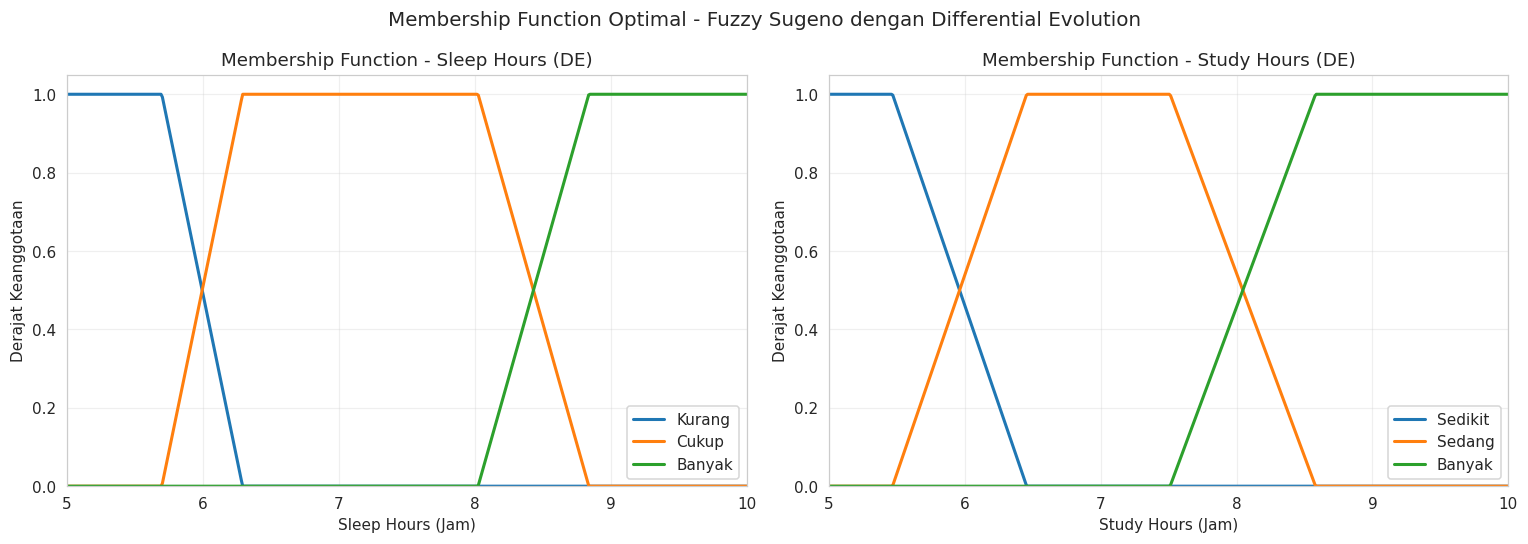

In [16]:

# ============================================================
# VISUALISASI MEMBERSHIP FUNCTION OPTIMAL HASIL DE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sleep Hours
x_tidur = np.linspace(
    BATAS_DOMAIN["tidur"][0],
    BATAS_DOMAIN["tidur"][1],
    500
)

for nama, parameter in HIMPUNAN_SUGENO["tidur"].items():
    axes[0].plot(
        x_tidur,
        trapmf_vec(x_tidur, parameter),
        linewidth=2,
        label=nama
    )

axes[0].set_title("Membership Function - Sleep Hours (DE)")
axes[0].set_xlabel("Sleep Hours (Jam)")
axes[0].set_ylabel("Derajat Keanggotaan")
axes[0].set_ylim(0, 1.05)
axes[0].set_xlim(*BATAS_DOMAIN["tidur"])
axes[0].legend()
axes[0].grid(alpha=0.3)


# Study Hours
x_belajar = np.linspace(
    BATAS_DOMAIN["belajar"][0],
    BATAS_DOMAIN["belajar"][1],
    500
)

for nama, parameter in HIMPUNAN_SUGENO["belajar"].items():
    axes[1].plot(
        x_belajar,
        trapmf_vec(x_belajar, parameter),
        linewidth=2,
        label=nama
    )

axes[1].set_title("Membership Function - Study Hours (DE)")
axes[1].set_xlabel("Study Hours (Jam)")
axes[1].set_ylabel("Derajat Keanggotaan")
axes[1].set_ylim(0, 1.05)
axes[1].set_xlim(*BATAS_DOMAIN["belajar"])
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Membership Function Optimal - Fuzzy Sugeno dengan Differential Evolution",
    fontsize=13
)

plt.tight_layout()
plt.show()


## 9.1 Perbandingan MF Baseline (Kuantil) vs MF Optimal (DE)
Garis putus-putus = MF baseline dari sub-training, garis tegas = MF hasil optimasi DE.

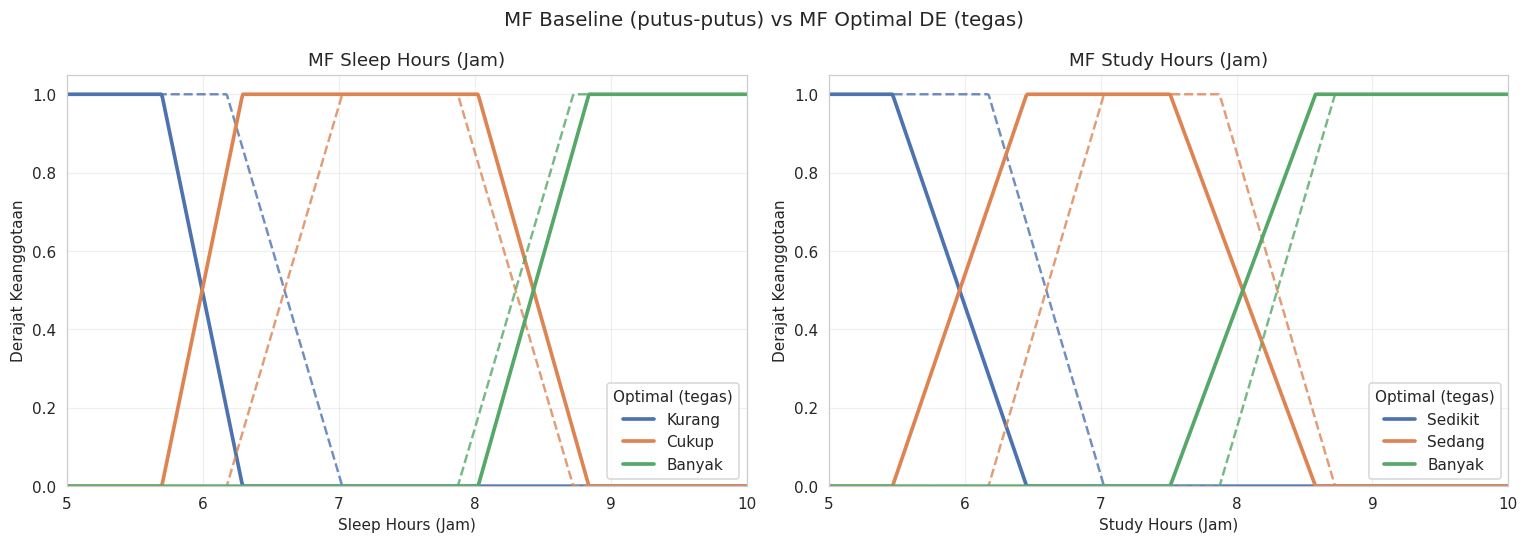

,Parameter,Baseline,Optimal DE,Selisih
0,"Tidur: Kurang→Cukup (batas bawah, c1)",6.175,5.6971,-0.4779
1,"Tidur: Kurang→Cukup (batas atas, c2)",7.025,6.2914,-0.7336
2,"Tidur: Cukup→Banyak (batas bawah, c3)",7.875,8.0241,0.1491
3,"Tidur: Cukup→Banyak (batas atas, c4)",8.725,8.8391,0.1141
4,"Belajar: Sedikit→Sedang (batas bawah, c1)",6.175,5.4688,-0.7062
5,"Belajar: Sedikit→Sedang (batas atas, c2)",7.025,6.4558,-0.5692
6,"Belajar: Sedang→Banyak (batas bawah, c3)",7.875,7.5111,-0.3639
7,"Belajar: Sedang→Banyak (batas atas, c4)",8.725,8.5812,-0.1438


In [17]:
# ============================================================
# TAHAP 9.1: MF BASELINE vs MF OPTIMAL
# ============================================================
MF_BASELINE = bentuk_mf_optimasi(THETA_AWAL)     # parameter awal (kuantil sub-training)
MF_OPTIMAL  = bentuk_mf_optimasi(THETA_OPT_V3)   # parameter hasil DE

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
konfig = [("tidur",   COL_TIDUR,   "Sleep Hours (Jam)"),
          ("belajar", COL_BELAJAR, "Study Hours (Jam)")]
warna_mf = ["#4C72B0", "#DD8452", "#55A868"]

for ax, (var, kol, judul) in zip(axes, konfig):
    L, U = BATAS_DOMAIN[var]
    x = np.linspace(L, U, 600)
    for w, nama in zip(warna_mf, MF_OPTIMAL[var].keys()):
        ax.plot(x, trapmf_vec(x, MF_BASELINE[var][nama]), "--", color=w, linewidth=1.6, alpha=0.8)
        ax.plot(x, trapmf_vec(x, MF_OPTIMAL[var][nama]),  "-",  color=w, linewidth=2.4, label=nama)
    ax.set_title(f"MF {judul}")
    ax.set_xlabel(judul)
    ax.set_ylabel("Derajat Keanggotaan")
    ax.set_ylim(0, 1.05)
    ax.set_xlim(L, U)
    ax.legend(title="Optimal (tegas)")

plt.suptitle("MF Baseline (putus-putus) vs MF Optimal DE (tegas)", fontsize=13)
plt.tight_layout()
plt.show()

# Tabel parameter sebelum & sesudah optimasi
nama_param = ["Tidur: Kurang→Cukup (batas bawah, c1)", "Tidur: Kurang→Cukup (batas atas, c2)",
              "Tidur: Cukup→Banyak (batas bawah, c3)", "Tidur: Cukup→Banyak (batas atas, c4)",
              "Belajar: Sedikit→Sedang (batas bawah, c1)", "Belajar: Sedikit→Sedang (batas atas, c2)",
              "Belajar: Sedang→Banyak (batas bawah, c3)", "Belajar: Sedang→Banyak (batas atas, c4)"]
tabel_param = pd.DataFrame({
    "Parameter": nama_param,
    "Baseline":  np.round(THETA_AWAL, 4),
    "Optimal DE": np.round(THETA_OPT_V3, 4),
})
tabel_param["Selisih"] = (tabel_param["Optimal DE"] - tabel_param["Baseline"]).round(4)
display(tabel_param)

# 10. Studi Kasus Manual (3 Mahasiswa)
Perhitungan Sugeno orde nol dilakukan langkah demi langkah untuk **tiga mahasiswa dengan profil berbeda**, sehingga masing-masing menghasilkan kategori stres yang berbeda (Low, Moderate, High):

| Mahasiswa | Profil | Dugaan kategori |
|---|---|---|
| A | Tidur cukup, belajar sedikit | Low |
| B | Tidur cukup, belajar sedang | Moderate |
| C | Tidur kurang, belajar sedang | High |

Nilai input dipilih agar jatuh pada himpunan fuzzy yang berbeda. Kategori akhir tetap ditentukan oleh perhitungan, bukan oleh dugaan di atas.

In [18]:
# ============================================================
# TAHAP 7: STUDI KASUS MANUAL - 3 MAHASISWA
# ============================================================

# (nama, Sleep Hours, Study Hours)
MAHASISWA = [
    ("Mahasiswa A", 8.0, 5.5),   # tidur cukup, belajar sedikit  -> diharapkan Low
    ("Mahasiswa B", 7.5, 6.5),   # tidur cukup, belajar sedang   -> diharapkan Moderate
    ("Mahasiswa C", 5.8, 7.0),   # tidur kurang, belajar sedang  -> diharapkan High
]


def hitung_manual(nama, T, B, tampil=True):
    """Inferensi Sugeno orde nol langkah demi langkah untuk satu mahasiswa."""
    mu_tidur = {n: float(trapmf_vec(np.array([T]), p)[0])
                for n, p in HIMPUNAN_SUGENO["tidur"].items()}
    mu_belajar = {n: float(trapmf_vec(np.array([B]), p)[0])
                  for n, p in HIMPUNAN_SUGENO["belajar"].items()}

    aktif = []
    for no, hb, ht, output in RULE_BASE:
        w = min(mu_belajar[hb], mu_tidur[ht])
        aktif.append((no, hb, ht, output, mu_belajar[hb], mu_tidur[ht], w))

    pembilang = sum(w * KONSEKUEN[out] for _, _, _, out, _, _, w in aktif)
    penyebut  = sum(w for *_, w in aktif)
    z         = pembilang / penyebut if penyebut > 0 else SKOR_DEFAULT
    kelas     = klasifikasi_output(z)

    if tampil:
        print("=" * 66)
        print(f"  {nama}: Sleep Hours = {T}  |  Study Hours = {B}")
        print("=" * 66)
        print("\n[1] Derajat Keanggotaan (Fuzzifikasi)")
        print("  Sleep Hours (Tidur)  :")
        for k, v in mu_tidur.items():
            print(f"    mu_{k:<8} = {v:.4f}")
        print("  Study Hours (Belajar):")
        for k, v in mu_belajar.items():
            print(f"    mu_{k:<8} = {v:.4f}")

        print("\n[2-3] Aturan Aktif & Firing Strength")
        print(f"  {'No.':<5} {'Study':<10} {'Sleep':<10} {'Output':<10} "
              f"{'mu_study':<10} {'mu_sleep':<10} {'w_i'}")
        print("  " + "-" * 68)
        for no, hb, ht, output, mb, mt, w in aktif:
            flag = " ✓" if w > 0 else ""
            print(f"  R{no:<4} {hb:<10} {ht:<10} {output:<10} "
                  f"{mb:<10.4f} {mt:<10.4f} {w:.4f}{flag}")

        print("\n[4] Perhitungan Weighted Average (hanya aturan aktif)")
        for no, hb, ht, output, _, _, w in aktif:
            if w > 0:
                print(f"  R{no}: w = {w:.4f} x z = {KONSEKUEN[output]}")
        print(f"  Sum(w_i x z_i) = {pembilang:.4f}")
        print(f"  Sum(w_i)       = {penyebut:.4f}")
        print(f"  z              = {pembilang:.4f} / {penyebut:.4f} = {z:.4f}")

        print("\n[5] Klasifikasi Akhir")
        print(f"  z = {z:.4f}  ->  Kategori: [{kelas}]")
        print("  (Low: 0-32.5 | Moderate: 32.5-67.5 | High: 67.5-100)")
        print("=" * 66 + "\n")

    return {"nama": nama, "T": T, "B": B, "mu_tidur": mu_tidur,
            "mu_belajar": mu_belajar, "z": z, "kelas": kelas}


# ------------------------------------------------------------
# Pengaman: ketiga mahasiswa harus menghasilkan kategori berbeda.
# Jika MF hasil DE di komputer Anda menggeser batas sehingga ada kategori
# yang kembar, input diganti otomatis dengan data nyata dari sub-training
# yang skor z-nya paling dekat dengan konsekuen kelas (15 / 50 / 85).
# ------------------------------------------------------------
KELAS_TARGET = ["Low", "Moderate", "High"]
hasil_cek = [hitung_manual(n, t, b, tampil=False)["kelas"] for n, t, b in MAHASISWA]

if hasil_cek != KELAS_TARGET:
    print("Input awal belum menghasilkan Low/Moderate/High, "
          "memilih contoh dari data sub-training...\n")
    z_tf, pred_tf = prediksi_sugeno_v3_final(train_fit, THETA_OPT_V3)
    baru = []
    for nama, target in zip(["Mahasiswa A", "Mahasiswa B", "Mahasiswa C"], KELAS_TARGET):
        idx = np.where(pred_tf == target)[0]
        j = idx[np.argmin(np.abs(z_tf[idx] - SKOR_KELAS[target]))]
        baru.append((nama,
                     round(float(train_fit.loc[j, COL_TIDUR]), 1),
                     round(float(train_fit.loc[j, COL_BELAJAR]), 1)))
    MAHASISWA = baru

HASIL_KASUS = [hitung_manual(n, t, b) for n, t, b in MAHASISWA]

# Ringkasan perbandingan tiga mahasiswa
ringkasan = pd.DataFrame([{
    "Mahasiswa": h["nama"],
    "Sleep (jam)": h["T"],
    "Study (jam)": h["B"],
    "Tidur dominan": max(h["mu_tidur"], key=h["mu_tidur"].get),
    "Belajar dominan": max(h["mu_belajar"], key=h["mu_belajar"].get),
    "z": round(h["z"], 2),
    "Kategori": h["kelas"],
} for h in HASIL_KASUS]).set_index("Mahasiswa")
print("RINGKASAN STUDI KASUS")
display(ringkasan)

assert len(set(ringkasan["Kategori"])) == 3, "Ketiga mahasiswa harus punya kategori berbeda"

  Mahasiswa A: Sleep Hours = 8.0  |  Study Hours = 5.5

[1] Derajat Keanggotaan (Fuzzifikasi)
  Sleep Hours (Tidur)  :
    mu_Kurang   = 0.0000
    mu_Cukup    = 1.0000
    mu_Banyak   = 0.0000
  Study Hours (Belajar):
    mu_Sedikit  = 0.9683
    mu_Sedang   = 0.0317
    mu_Banyak   = 0.0000

[2-3] Aturan Aktif & Firing Strength
  No.   Study      Sleep      Output     mu_study   mu_sleep   w_i
  --------------------------------------------------------------------
  R1    Sedikit    Kurang     High       0.9683     0.0000     0.0000
  R2    Sedikit    Cukup      Low        0.9683     1.0000     0.9683 ✓
  R3    Sedikit    Banyak     Low        0.9683     0.0000     0.0000
  R4    Sedang     Kurang     High       0.0317     0.0000     0.0000
  R5    Sedang     Cukup      Moderate   0.0317     1.0000     0.0317 ✓
  R6    Sedang     Banyak     Moderate   0.0317     0.0000     0.0000
  R7    Banyak     Kurang     High       0.0000     0.0000     0.0000
  R8    Banyak     Cukup      High  

,Sleep (jam),Study (jam),Tidur dominan,Belajar dominan,z,Kategori
Mahasiswa,,,,,,
Mahasiswa A,8.0,5.5,Cukup,Sedikit,16.11,Low
Mahasiswa B,7.5,6.5,Cukup,Sedang,50.00,Moderate
Mahasiswa C,5.8,7.0,Kurang,Sedang,78.94,High


## 10.1 Verifikasi Studi Kasus Manual vs Fungsi Prediksi
Hasil perhitungan manual ketiga mahasiswa (langkah demi langkah di atas) harus sama dengan keluaran fungsi `prediksi_sugeno_v3_final`.

In [19]:
# ============================================================
# TAHAP 10.1: KESESUAIAN PERHITUNGAN MANUAL vs IMPLEMENTASI
# ============================================================
df_kasus = pd.DataFrame({
    COL_TIDUR:   [h["T"] for h in HASIL_KASUS],
    COL_BELAJAR: [h["B"] for h in HASIL_KASUS],
})
z_fungsi, kelas_fungsi = prediksi_sugeno_v3_final(df_kasus, THETA_OPT_V3)

print(f"{'Mahasiswa':<13}{'Sleep':<8}{'Study':<8}{'z manual':<12}{'z fungsi':<12}{'Selisih':<12}{'Manual':<10}{'Fungsi'}")
print("-" * 85)
for h, zf, kf in zip(HASIL_KASUS, z_fungsi, kelas_fungsi):
    print(f"{h['nama']:<13}{h['T']:<8}{h['B']:<8}{h['z']:<12.6f}{zf:<12.6f}"
          f"{abs(h['z'] - zf):<12.2e}{h['kelas']:<10}{kf}")
    assert np.isclose(h["z"], zf, atol=1e-9), f"Skor {h['nama']} berbeda dengan fungsi prediksi!"
    assert h["kelas"] == kf, f"Kategori {h['nama']} berbeda dengan fungsi prediksi!"

print("\nSeluruh hasil implementasi SESUAI dengan perhitungan manual.")

# Opsional: bandingkan dengan hitungan tangan (kalkulator / Excel) per mahasiswa.
# Isi nilai z hasil hitungan tangan, lalu jalankan ulang sel ini.
Z_HITUNG_TANGAN = {"Mahasiswa A": None, "Mahasiswa B": None, "Mahasiswa C": None}
for h, zf in zip(HASIL_KASUS, z_fungsi):
    zt = Z_HITUNG_TANGAN.get(h["nama"])
    if zt is not None:
        print(f"{h['nama']}: z hitungan tangan = {zt} | selisih terhadap kode = {abs(zt - zf):.4f}")
        assert abs(zt - zf) < 0.01, f"Hitungan tangan {h['nama']} berbeda dari kode (cek pembulatan / parameter MF)"

Mahasiswa    Sleep   Study   z manual    z fungsi    Selisih     Manual    Fungsi
-------------------------------------------------------------------------------------
Mahasiswa A  8.0     5.5     16.107902   16.107902   0.00e+00    Low       Low
Mahasiswa B  7.5     6.5     50.000000   50.000000   0.00e+00    Moderate  Moderate
Mahasiswa C  5.8     7.0     78.941360   78.941360   0.00e+00    High      High

Seluruh hasil implementasi SESUAI dengan perhitungan manual.


# 11. Evaluasi Model

HASIL EVALUASI MODEL FUZZY SUGENO DENGAN DE


,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
Sub-training,0.9821,0.9847,0.9777,0.9811
Validation,0.9893,0.9897,0.9762,0.9824
Testing,0.9867,0.9877,0.9801,0.9837



CLASSIFICATION REPORT — TESTING
              precision    recall  f1-score   support

         Low       1.00      0.96      0.98        89
    Moderate       0.97      1.00      0.98       202
        High       1.00      0.99      0.99       309

    accuracy                           0.99       600
   macro avg       0.99      0.98      0.98       600
weighted avg       0.99      0.99      0.99       600



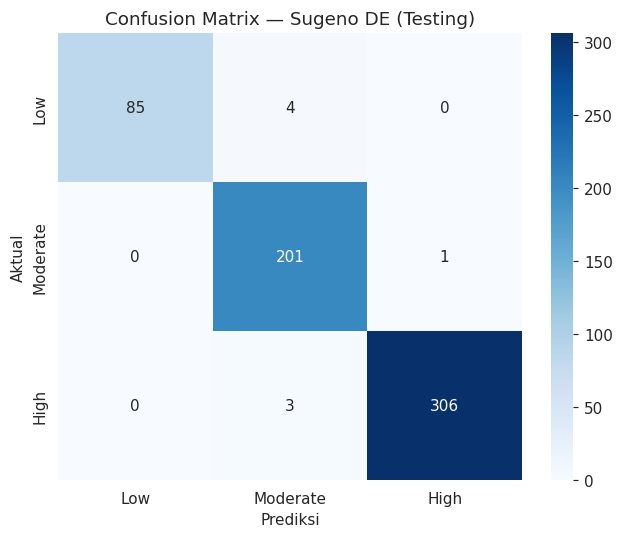

In [20]:

# ============================================================
# TAHAP 11: EVALUASI MODEL SUGENO DENGAN DE
# ============================================================

# Prediksi Sub-training, Validation, dan Testing
z_train, pred_train = prediksi_sugeno_v3_final(
    train_fit, THETA_OPT_V3
)

z_valid, pred_valid = prediksi_sugeno_v3_final(
    validation, THETA_OPT_V3
)

z_test, pred_test = prediksi_sugeno_v3_final(
    test, THETA_OPT_V3
)

# Label aktual
y_train_true = train_fit[COL_LABEL].to_numpy()
y_valid_true = validation[COL_LABEL].to_numpy()
y_test_true = test[COL_LABEL].to_numpy()


# Fungsi evaluasi
def evaluasi_model(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(
            y_true, y_pred,
            labels=KELAS,
            average="macro",
            zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred,
            labels=KELAS,
            average="macro",
            zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_true, y_pred,
            labels=KELAS,
            average="macro",
            zero_division=0
        )
    }


# Tabel evaluasi
hasil_evaluasi = pd.DataFrame({
    "Sub-training": evaluasi_model(
        y_train_true, pred_train
    ),
    "Validation": evaluasi_model(
        y_valid_true, pred_valid
    ),
    "Testing": evaluasi_model(
        y_test_true, pred_test
    )
}).T

print("=" * 65)
print("HASIL EVALUASI MODEL FUZZY SUGENO DENGAN DE")
print("=" * 65)

display(hasil_evaluasi.round(4))


# Classification Report Testing
print("\nCLASSIFICATION REPORT — TESTING")

print(classification_report(
    y_test_true,
    pred_test,
    labels=KELAS,
    target_names=KELAS,
    zero_division=0
))


# Confusion Matrix Testing
cm_test = confusion_matrix(
    y_test_true,
    pred_test,
    labels=KELAS
)

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=KELAS,
    yticklabels=KELAS,
    ax=ax
)

ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
ax.set_title("Confusion Matrix — Sugeno DE (Testing)")

plt.tight_layout()
plt.show()


## 11.1 Perbandingan Model Baseline (Sebelum DE) vs Model DE
Membuktikan bahwa optimasi DE benar-benar memperbaiki kinerja dibandingkan MF awal dari kuantil sub-training.

Accuracy  Precision (Macro)  Recall (Macro)  \
Model              Data                                                        
Baseline (kuantil) Sub-training    0.7938             0.7451          0.7693   
                   Validation      0.8107             0.7680          0.7805   
                   Testing         0.8333             0.7915          0.8091   
DE (optimal)       Sub-training    0.9821             0.9847          0.9777   
                   Validation      0.9893             0.9897          0.9762   
                   Testing         0.9867             0.9877          0.9801   

                                 F1-Score (Macro)  
Model              Data                            
Baseline (kuantil) Sub-training            0.7465  
                   Validation              0.7665  
                   Testing                 0.7919  
DE (optimal)       Sub-training            0.9811  
                   Validation              0.9824  
                   Testing                 0.9837

Peningkatan pada data testing (DE - Baseline):


,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
Selisih,0.1533,0.1962,0.1711,0.1918


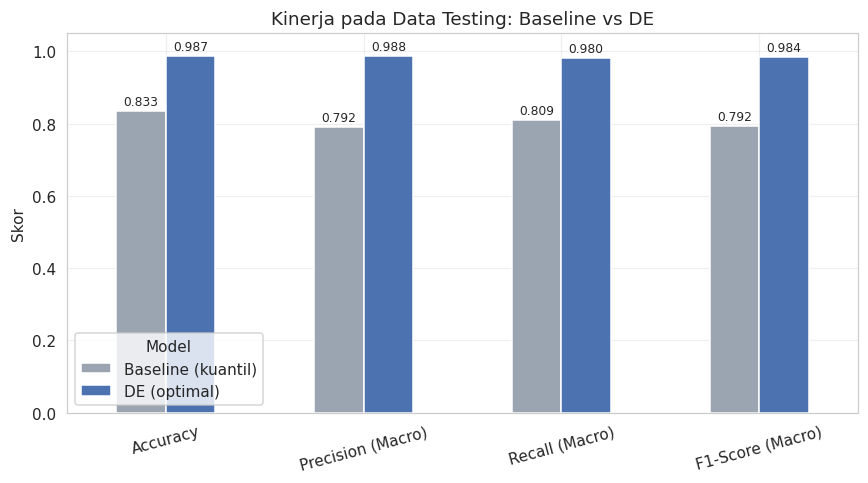

In [21]:
# ============================================================
# TAHAP 11.1: BASELINE vs DE
# ============================================================
bagian_data = {
    "Sub-training": (train_fit,  y_train_true),
    "Validation":   (validation, y_valid_true),
    "Testing":      (test,       y_test_true),
}

baris = []
for nama_model, theta in [("Baseline (kuantil)", THETA_AWAL), ("DE (optimal)", THETA_OPT_V3)]:
    for nama_bagian, (d, y) in bagian_data.items():
        _, p = prediksi_sugeno_v3_final(d, theta)
        m = evaluasi_model(y, p)
        baris.append({"Model": nama_model, "Data": nama_bagian, **m})

banding = pd.DataFrame(baris).set_index(["Model", "Data"])
display(banding.round(4))

# Selisih (DE - Baseline) pada data testing
sel = (banding.loc[("DE (optimal)", "Testing")] - banding.loc[("Baseline (kuantil)", "Testing")]).round(4)
print("Peningkatan pada data testing (DE - Baseline):")
display(sel.to_frame("Selisih").T)

# Grafik batang pada data testing
uji = banding.xs("Testing", level="Data")
ax = uji.T.plot(kind="bar", figsize=(8, 4.5), rot=15, color=["#9AA5B1", "#4C72B0"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Skor")
ax.set_title("Kinerja pada Data Testing: Baseline vs DE")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.show()

## 11.2 Confusion Matrix Sub-training, Validation, dan Testing
Perbandingan ketiga bagian data membantu mengecek apakah model overfit terhadap validation.

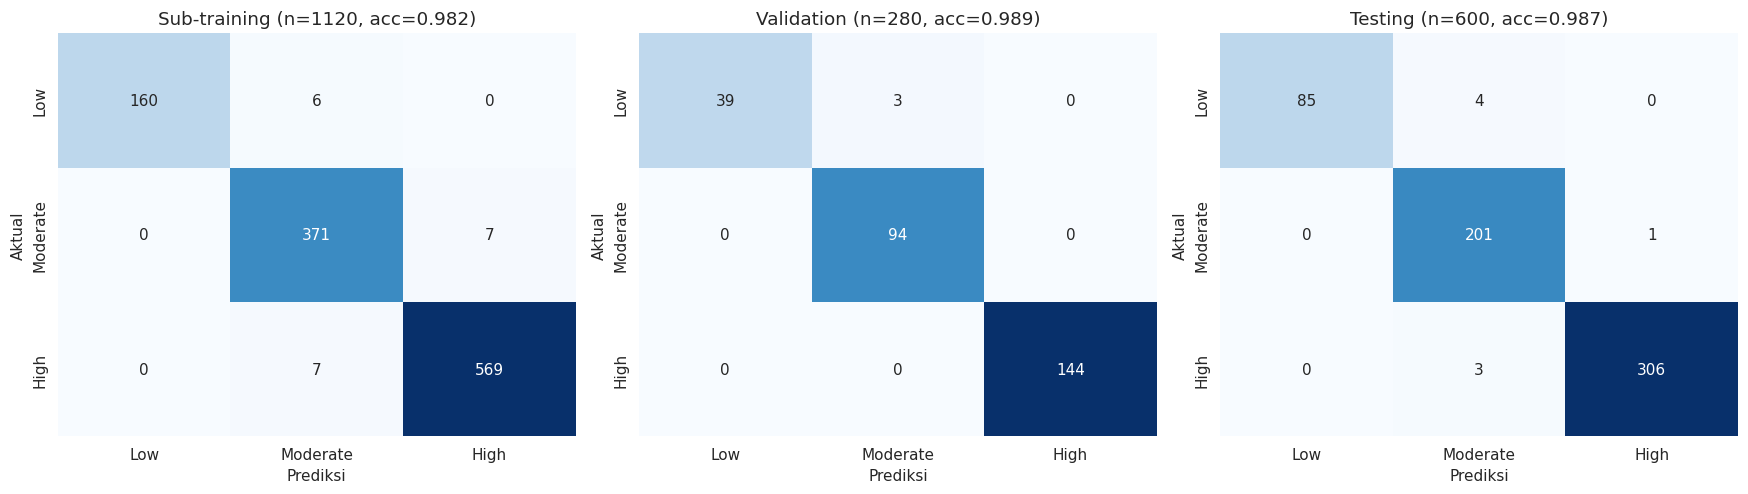

In [22]:
# ============================================================
# TAHAP 11.2: CONFUSION MATRIX SEMUA BAGIAN DATA
# ============================================================
prediksi_bagian = {
    "Sub-training": pred_train,
    "Validation":   pred_valid,
    "Testing":      pred_test,
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (nama_bagian, (d, y)) in zip(axes, bagian_data.items()):
    cm = confusion_matrix(y, prediksi_bagian[nama_bagian], labels=KELAS)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=KELAS, yticklabels=KELAS, ax=ax)
    acc = accuracy_score(y, prediksi_bagian[nama_bagian])
    ax.set_title(f"{nama_bagian} (n={len(y)}, acc={acc:.3f})")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()

## 11.3 Pemeriksaan Kelengkapan Pemrosesan Data Testing
Memastikan seluruh 600 data testing berhasil diproses: tidak ada nilai kosong, skor berada dalam rentang konsekuen, dan tidak ada data yang jatuh ke nilai default akibat total firing strength nol.

In [23]:
# ============================================================
# TAHAP 11.3: PEMERIKSAAN KELENGKAPAN PEMROSESAN
# ============================================================
def hitung_firing(df_input, theta):
    """Mengembalikan derajat keanggotaan dan firing strength tiap aturan."""
    mf = bentuk_mf_optimasi(theta)
    T = df_input[COL_TIDUR].to_numpy(dtype=float)
    B = df_input[COL_BELAJAR].to_numpy(dtype=float)
    mu_t = {n: trapmf_vec(T, p) for n, p in mf["tidur"].items()}
    mu_b = {n: trapmf_vec(B, p) for n, p in mf["belajar"].items()}
    firing = np.column_stack([np.minimum(mu_b[hb], mu_t[ht]) for _, hb, ht, _ in RULE_BASE])
    return mu_t, mu_b, firing

mu_t_test, mu_b_test, firing_test = hitung_firing(test, THETA_OPT_V3)
total_firing = firing_test.sum(axis=1)

L_t, U_t = BATAS_DOMAIN["tidur"]
L_b, U_b = BATAS_DOMAIN["belajar"]
di_luar_domain = ((test[COL_TIDUR] < L_t) | (test[COL_TIDUR] > U_t) |
                  (test[COL_BELAJAR] < L_b) | (test[COL_BELAJAR] > U_b)).sum()

pemeriksaan = pd.Series({
    "Jumlah data testing":                         len(test),
    "Jumlah prediksi dihasilkan":                  len(pred_test),
    "Skor z bernilai NaN":                         int(np.isnan(z_test).sum()),
    "Skor z di luar rentang [15, 85]":             int(((z_test < 15 - 1e-9) | (z_test > 85 + 1e-9)).sum()),
    "Input di luar domain MF":                     int(di_luar_domain),
    "Total firing = 0 (jatuh ke SKOR_DEFAULT)":    int((total_firing == 0).sum()),
    "Kelas prediksi tak dikenal":                  int((~pd.Series(pred_test).isin(KELAS)).sum()),
}, name="Hasil")
display(pemeriksaan.to_frame())

assert len(pred_test) == len(test) == 600
assert pemeriksaan["Skor z bernilai NaN"] == 0
assert pemeriksaan["Total firing = 0 (jatuh ke SKOR_DEFAULT)"] == 0
assert pemeriksaan["Kelas prediksi tak dikenal"] == 0
print("Seluruh 600 data testing berhasil diproses.")

,Hasil
Jumlah data testing,600
Jumlah prediksi dihasilkan,600
Skor z bernilai NaN,0
"Skor z di luar rentang [15, 85]",0
Input di luar domain MF,0
Total firing = 0 (jatuh ke SKOR_DEFAULT),0
Kelas prediksi tak dikenal,0


Seluruh 600 data testing berhasil diproses.


## 11.4 Distribusi Hasil Prediksi
Perbandingan jumlah data per kelas antara label aktual dan hasil prediksi model pada data testing.

,Aktual,Prediksi,Aktual (%),Prediksi (%)
Low,89,85,14.8,14.2
Moderate,202,208,33.7,34.7
High,309,307,51.5,51.2


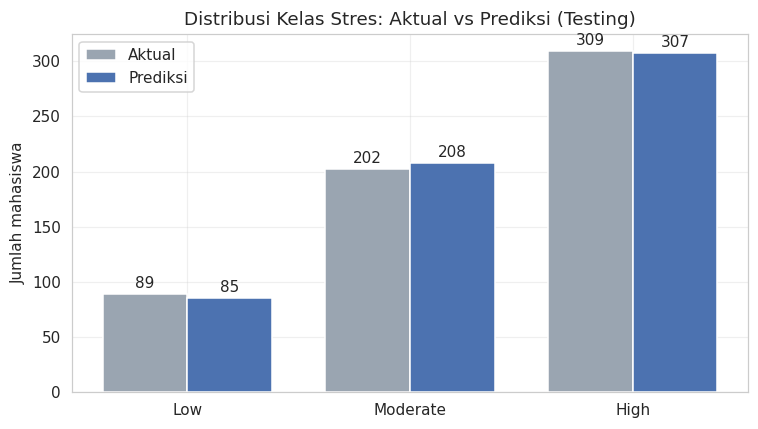

In [24]:
# ============================================================
# TAHAP 11.4: DISTRIBUSI PREDIKSI vs AKTUAL (TESTING)
# ============================================================
dist = pd.DataFrame({
    "Aktual":   pd.Series(y_test_true).value_counts().reindex(KELAS),
    "Prediksi": pd.Series(pred_test).value_counts().reindex(KELAS).fillna(0).astype(int),
})
dist["Aktual (%)"]   = (dist["Aktual"]   / dist["Aktual"].sum()   * 100).round(1)
dist["Prediksi (%)"] = (dist["Prediksi"] / dist["Prediksi"].sum() * 100).round(1)
display(dist)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(KELAS)); lebar = 0.38
b1 = ax.bar(x - lebar/2, dist["Aktual"],   lebar, label="Aktual",   color="#9AA5B1")
b2 = ax.bar(x + lebar/2, dist["Prediksi"], lebar, label="Prediksi", color="#4C72B0")
ax.bar_label(b1, padding=2); ax.bar_label(b2, padding=2)
ax.set_xticks(x); ax.set_xticklabels(KELAS)
ax.set_ylabel("Jumlah mahasiswa")
ax.set_title("Distribusi Kelas Stres: Aktual vs Prediksi (Testing)")
ax.legend()
plt.tight_layout()
plt.show()

## 11.5 Contoh Hasil Inferensi
Tabel berikut menampilkan contoh dari tiap kelas yang diprediksi benar, serta **seluruh data yang salah prediksi**, lengkap dengan derajat keanggotaan, aturan yang paling berpengaruh, dan skor Sugeno.

In [25]:
# ============================================================
# TAHAP 11.5: CONTOH HASIL INFERENSI (BENAR & SALAH)
# ============================================================
nama_aturan = [f"R{no}" for no, *_ in RULE_BASE]

df_inf = test[[COL_TIDUR, COL_BELAJAR, COL_LABEL]].copy().reset_index(drop=True)
df_inf.columns = ["Sleep", "Study", "Aktual"]
for n in HIMP_TIDUR:
    df_inf[f"μ Tidur-{n}"] = mu_t_test[n].round(3)
for n in HIMP_BELAJAR:
    df_inf[f"μ Belajar-{n}"] = mu_b_test[n].round(3)
df_inf["Aturan dominan"] = [nama_aturan[i] for i in firing_test.argmax(axis=1)]
df_inf["w maks"]         = firing_test.max(axis=1).round(3)
df_inf["z"]              = np.round(z_test, 3)
df_inf["Prediksi"]       = pred_test
df_inf["Benar"]          = df_inf["Aktual"] == df_inf["Prediksi"]

contoh_benar = (df_inf[df_inf["Benar"]].groupby("Aktual", group_keys=False)
                  .head(2).sort_values("Aktual", key=lambda s: s.map({k: i for i, k in enumerate(KELAS)})))
contoh_salah = df_inf[~df_inf["Benar"]]

print("Contoh prediksi BENAR (2 per kelas):")
display(contoh_benar)
print(f"\nSeluruh prediksi SALAH ({len(contoh_salah)} data):")
display(contoh_salah)

Contoh prediksi BENAR (2 per kelas):


,Sleep,Study,Aktual,μ Tidur-Kurang,μ Tidur-Cukup,μ Tidur-Banyak,μ Belajar-Sedikit,μ Belajar-Sedang,μ Belajar-Banyak,Aturan dominan,w maks,z,Prediksi,Benar
10,6.2,5.3,Low,0.154,0.846,0.0,1.000,0.000,0.000,R2,0.846,25.764,Low,True
6,8.9,5.2,Low,0.000,0.000,1.0,1.000,0.000,0.000,R3,1.000,15.000,Low,True
0,7.9,6.1,Moderate,0.000,1.000,0.0,0.360,0.640,0.000,R5,0.640,37.384,Moderate,True
1,9.6,6.3,Moderate,0.000,0.000,1.0,0.158,0.842,0.000,R6,0.842,44.476,Moderate,True
3,6.0,8.3,High,0.490,0.510,0.0,0.000,0.263,0.737,R8,0.510,78.971,High,True
2,5.3,6.5,High,1.000,0.000,0.0,0.000,1.000,0.000,R4,1.000,85.000,High,True



Seluruh prediksi SALAH (8 data):


,Sleep,Study,Aktual,μ Tidur-Kurang,μ Tidur-Cukup,μ Tidur-Banyak,μ Belajar-Sedikit,μ Belajar-Sedang,μ Belajar-Banyak,Aturan dominan,w maks,z,Prediksi,Benar
45,6.1,5.6,Low,0.322,0.678,0.0,0.867,0.133,0.000,R2,0.678,43.837,Moderate,False
78,5.9,5.0,High,0.659,0.341,0.0,1.000,0.000,0.000,R1,0.659,61.103,Moderate,False
235,6.0,5.7,Low,0.490,0.510,0.0,0.766,0.234,0.000,R2,0.510,55.123,Moderate,False
297,5.9,5.3,High,0.659,0.341,0.0,1.000,0.000,0.000,R1,0.659,61.103,Moderate,False
332,6.1,5.4,Low,0.322,0.678,0.0,1.000,0.000,0.000,R2,0.678,37.544,Moderate,False
340,5.9,5.2,High,0.659,0.341,0.0,1.000,0.000,0.000,R1,0.659,61.103,Moderate,False
386,6.0,5.1,Low,0.490,0.510,0.0,1.000,0.000,0.000,R2,0.510,49.324,Moderate,False
571,6.0,7.6,Moderate,0.490,0.510,0.0,0.000,0.917,0.083,R5,0.510,69.703,High,False


## 11.6 Hubungan Input dengan Output (Permukaan Skor Sugeno)
Peta skor Sugeno terhadap kombinasi Sleep Hours dan Study Hours. Garis putus-putus menandai batas klasifikasi 32,5 dan 67,5. Titik-titik adalah data testing berdasarkan label aktual.

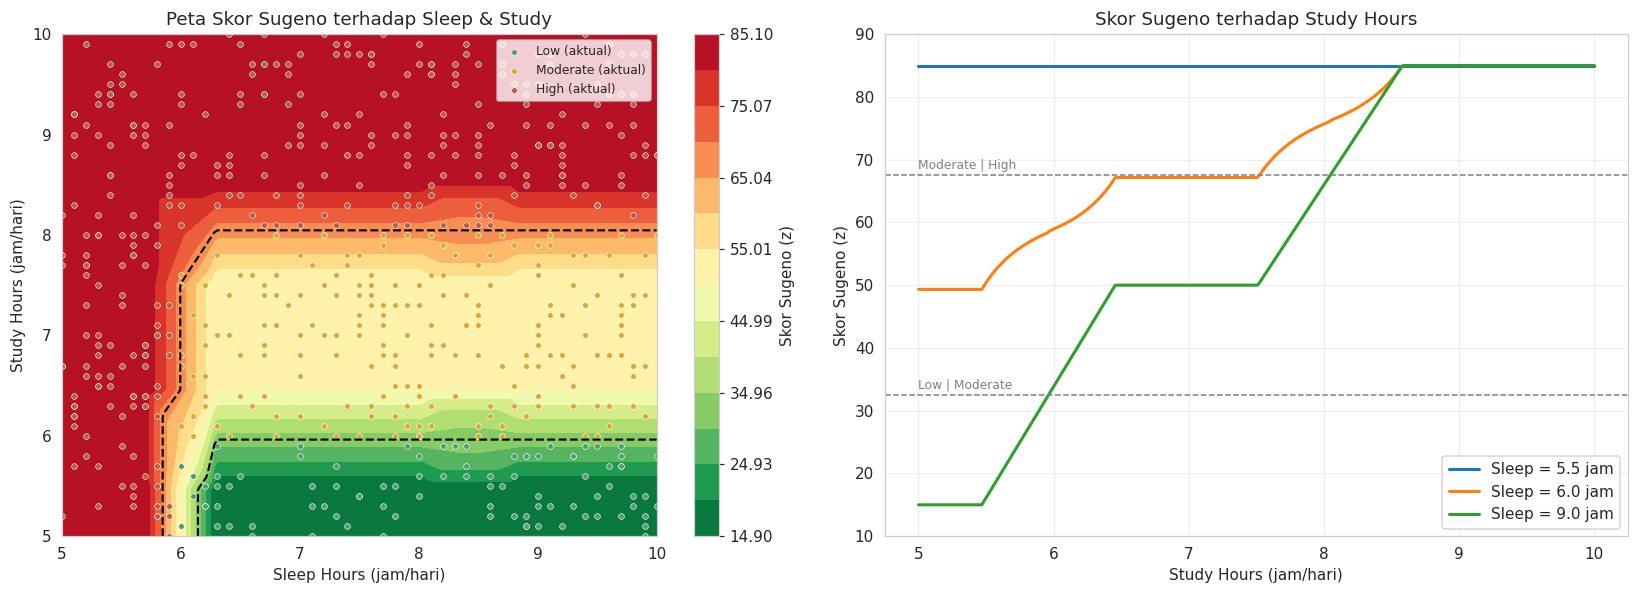

In [26]:
# ============================================================
# TAHAP 11.6: PERMUKAAN INPUT - OUTPUT
# ============================================================
gx = np.linspace(*BATAS_DOMAIN["tidur"],   200)
gy = np.linspace(*BATAS_DOMAIN["belajar"], 200)
GX, GY = np.meshgrid(gx, gy)
grid = pd.DataFrame({COL_TIDUR: GX.ravel(), COL_BELAJAR: GY.ravel()})
z_grid, _ = prediksi_sugeno_v3_final(grid, THETA_OPT_V3)
Z = z_grid.reshape(GX.shape)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# (a) Peta skor z
ax = axes[0]
cs = ax.contourf(GX, GY, Z, levels=np.linspace(14.9, 85.1, 15), cmap="RdYlGn_r")
fig.colorbar(cs, ax=ax, label="Skor Sugeno (z)")
ax.contour(GX, GY, Z, levels=[32.5, 67.5], colors="black", linestyles="--", linewidths=1.4)
for k in KELAS:
    sub_k = test[test[COL_LABEL] == k]
    ax.scatter(sub_k[COL_TIDUR], sub_k[COL_BELAJAR], s=14, edgecolor="white",
               linewidth=0.4, color=warna[k], label=f"{k} (aktual)")
ax.set_xlabel("Sleep Hours (jam/hari)")
ax.set_ylabel("Study Hours (jam/hari)")
ax.set_title("Peta Skor Sugeno terhadap Sleep & Study")
ax.legend(loc="upper right", fontsize=8)

# (b) Skor z terhadap Study pada beberapa level Sleep
ax = axes[1]
ys = np.linspace(*BATAS_DOMAIN["belajar"], 300)
for s_val in [5.5, 6.0, 9.0]:
    d_line = pd.DataFrame({COL_TIDUR: np.full_like(ys, s_val), COL_BELAJAR: ys})
    z_line, _ = prediksi_sugeno_v3_final(d_line, THETA_OPT_V3)
    ax.plot(ys, z_line, linewidth=2, label=f"Sleep = {s_val} jam")
ax.axhline(32.5, color="gray", linestyle="--", linewidth=1)
ax.axhline(67.5, color="gray", linestyle="--", linewidth=1)
ax.text(ys.min(), 33.5, "Low | Moderate", fontsize=8, color="gray")
ax.text(ys.min(), 68.5, "Moderate | High", fontsize=8, color="gray")
ax.set_xlabel("Study Hours (jam/hari)")
ax.set_ylabel("Skor Sugeno (z)")
ax.set_ylim(10, 90)
ax.set_title("Skor Sugeno terhadap Study Hours")
ax.legend()

plt.tight_layout()
plt.show()

# 12. Ekspor Hasil Prediksi

In [27]:

# ============================================================
# TAHAP 12: EKSPOR HASIL PREDIKSI TESTING
# ============================================================

# Membuat tabel hasil prediksi
df_hasil_test = test[
    [COL_TIDUR, COL_BELAJAR, COL_LABEL]
].copy()

df_hasil_test.rename(columns={
    COL_TIDUR: "Sleep_Hours",
    COL_BELAJAR: "Study_Hours",
    COL_LABEL: "Aktual"
}, inplace=True)

df_hasil_test["z_output"] = np.round(z_test, 4)
df_hasil_test["Prediksi"] = pred_test

df_hasil_test["Benar"] = (
    df_hasil_test["Aktual"] ==
    df_hasil_test["Prediksi"]
)

# Menampilkan hasil
print("TABEL HASIL PREDIKSI — DATA TESTING")
display(df_hasil_test.head(10))


# Ekspor CSV
CSV_DIR  = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
CSV_PATH = os.path.join(CSV_DIR, "prediksi_testing_sugeno_DE.csv")

df_hasil_test.to_csv(
    CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 55)
print("EKSPOR BERHASIL")
print("=" * 55)

print("File       :", CSV_PATH)
print("Jumlah data:", len(df_hasil_test))
print("Benar      :", df_hasil_test["Benar"].sum())
print("Salah      :", (~df_hasil_test["Benar"]).sum())


TABEL HASIL PREDIKSI — DATA TESTING


,Sleep_Hours,Study_Hours,Aktual,z_output,Prediksi,Benar
0,7.9,6.1,Moderate,37.3841,Moderate,True
1,9.6,6.3,Moderate,44.4761,Moderate,True
2,5.3,6.5,High,85.0000,High,True
3,6.0,8.3,High,78.9707,High,True
4,5.6,9.1,High,85.0000,High,True
5,8.1,8.4,High,77.2560,High,True
6,8.9,5.2,Low,15.0000,Low,True
7,6.7,9.7,High,85.0000,High,True
8,9.2,8.6,High,85.0000,High,True
9,8.3,7.8,Moderate,62.2713,Moderate,True



EKSPOR BERHASIL
File       : /kaggle/working/prediksi_testing_sugeno_DE.csv
Jumlah data: 600
Benar      : 592
Salah      : 8


# 13. Analisis Tambahan

Bagian ini bersifat pelengkap evaluasi (tidak mengubah model final): konvergensi dan kestabilan DE, serta pembanding dengan model klasifikasi sederhana.

## 13.1 Konvergensi dan Kestabilan Optimasi DE
DE dijalankan ulang dengan seed yang sama untuk merekam nilai fitness terbaik tiap generasi (hasilnya harus identik dengan `THETA_OPT_V3`). Kemudian DE dijalankan dengan beberapa seed lain **hanya untuk melihat kestabilan**; parameter final model tidak diganti.

Hasil ulang seed=42 identik dengan THETA_OPT_V3  -> OK


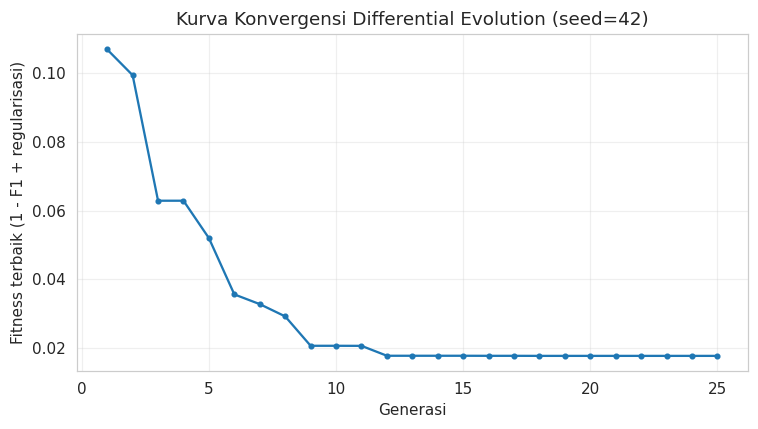

,Fitness DE,Val Acc,Test Acc,Test Macro-F1
Seed,,,,
1,0.0147,0.9893,0.9800,0.9797
7,0.0178,0.9893,0.9867,0.9823
21,0.0147,0.9893,0.9800,0.9811
42,0.0178,0.9893,0.9867,0.9837
99,0.0147,0.9893,0.9800,0.9797


Rata-rata Test Acc = 0.9827  |  Std = 0.0037


In [28]:
# ============================================================
# TAHAP 13.1: KONVERGENSI & KESTABILAN DE
# ============================================================
riwayat_fitness = []

def catat_konvergensi(xk, convergence=None):
    riwayat_fitness.append(objective_v3_fast(xk))

def jalankan_de(seed, callback=None):
    return differential_evolution(
        objective_v3_fast, bounds=BOUNDS_V3, strategy="best1bin",
        maxiter=25, popsize=6, mutation=(0.5, 1.0), recombination=0.7,
        tol=0.005, seed=seed, polish=False, workers=1, updating="immediate",
        callback=callback)

# --- (a) Ulang seed=42 dengan perekaman fitness tiap generasi ---
hasil_ulang = jalankan_de(42, callback=catat_konvergensi)
assert np.allclose(hasil_ulang.x, THETA_OPT_V3), "Hasil ulang berbeda dari THETA_OPT_V3"
print("Hasil ulang seed=42 identik dengan THETA_OPT_V3  -> OK")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(riwayat_fitness) + 1), riwayat_fitness, marker="o", markersize=3)
ax.set_xlabel("Generasi")
ax.set_ylabel("Fitness terbaik (1 - F1 + regularisasi)")
ax.set_title("Kurva Konvergensi Differential Evolution (seed=42)")
plt.tight_layout()
plt.show()

# --- (b) Kestabilan terhadap seed (hanya untuk pelaporan) ---
baris_seed = []
for sd in [1, 7, 21, 42, 99]:
    h = hasil_ulang if sd == 42 else jalankan_de(sd)
    _, p_val = prediksi_sugeno_v3_final(validation, h.x)
    _, p_tes = prediksi_sugeno_v3_final(test, h.x)
    baris_seed.append({
        "Seed": sd,
        "Fitness DE": round(h.fun, 4),
        "Val Acc":  round(accuracy_score(y_valid_true, p_val), 4),
        "Test Acc": round(accuracy_score(y_test_true, p_tes), 4),
        "Test Macro-F1": round(f1_score(y_test_true, p_tes, labels=KELAS, average="macro", zero_division=0), 4),
    })
tabel_seed = pd.DataFrame(baris_seed).set_index("Seed")
display(tabel_seed)
print(f"Rata-rata Test Acc = {tabel_seed['Test Acc'].mean():.4f}  |  "
      f"Std = {tabel_seed['Test Acc'].std():.4f}")

## 13.2 Pembanding dengan Model Klasifikasi Sederhana
Sebagai konteks (bukan pengganti model Sugeno), model Decision Tree dan Logistic Regression dilatih pada data train (1.400 baris) dan diuji pada data testing yang sama.

In [29]:
# ============================================================
# TAHAP 13.2: MODEL PEMBANDING
# ============================================================
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LogisticRegression

fitur = [COL_TIDUR, COL_BELAJAR]
X_tr, y_tr = train[fitur], train[COL_LABEL]
X_te, y_te = test[fitur],  test[COL_LABEL]

pembanding = {
    "Decision Tree (depth=3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "Decision Tree (depth=4)": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Logistic Regression":     LogisticRegression(max_iter=1000),
}

hasil_banding = {}
for nama_m, m in pembanding.items():
    m.fit(X_tr, y_tr)
    p = m.predict(X_te)
    hasil_banding[nama_m] = {
        "Accuracy":         accuracy_score(y_te, p),
        "F1-Score (Macro)": f1_score(y_te, p, labels=KELAS, average="macro", zero_division=0),
    }

# Tambahkan model fuzzy (testing) sebagai rujukan
for nama_m, theta in [("Sugeno Baseline (kuantil)", THETA_AWAL), ("Sugeno + DE (model final)", THETA_OPT_V3)]:
    _, p = prediksi_sugeno_v3_final(test, theta)
    hasil_banding[nama_m] = {
        "Accuracy":         accuracy_score(y_te, p),
        "F1-Score (Macro)": f1_score(y_te, p, labels=KELAS, average="macro", zero_division=0),
    }

display(pd.DataFrame(hasil_banding).T.round(4))

print("\nAturan Decision Tree (depth=3) untuk melihat pola pemisah kelas pada data:")
print(export_text(pembanding["Decision Tree (depth=3)"], feature_names=fitur))

,Accuracy,F1-Score (Macro)
Decision Tree (depth=3),1.0000,1.0000
Decision Tree (depth=4),1.0000,1.0000
Logistic Regression,0.8433,0.8422
Sugeno Baseline (kuantil),0.8333,0.7919
Sugeno + DE (model final),0.9867,0.9837



Aturan Decision Tree (depth=3) untuk melihat pola pemisah kelas pada data:
|--- Study_Hours_Per_Day <= 8.05
|   |--- Study_Hours_Per_Day <= 5.95
|   |   |--- Sleep_Hours_Per_Day <= 5.95
|   |   |   |--- class: High
|   |   |--- Sleep_Hours_Per_Day >  5.95
|   |   |   |--- class: Low
|   |--- Study_Hours_Per_Day >  5.95
|   |   |--- Sleep_Hours_Per_Day <= 5.95
|   |   |   |--- class: High
|   |   |--- Sleep_Hours_Per_Day >  5.95
|   |   |   |--- class: Moderate
|--- Study_Hours_Per_Day >  8.05
|   |--- class: High



# 14. Penjelasan Implementasi Kode

Ringkasan hubungan antara tahapan Sugeno dan fungsi pada notebook ini.

| Tahap | Fungsi / Variabel | Penjelasan |
|---|---|---|
| Data | `train_test_split` (3B, 4.1) | Split stratified: 1.400 train / 600 test, lalu train menjadi 1.120 sub-training / 280 validation. |
| MF baseline | `bentuk_mf_baseline` | Titik MF dari kuantil 1/3 dan 2/3 sub-training, ditambah zona transisi selebar seperempat jarak kuantil. |
| MF optimal | `bentuk_mf_optimasi(theta)` | Membentuk 3 MF tidur dan 3 MF belajar (trapesium) dari 8 parameter `theta`. |
| Fuzzifikasi | `trapmf_vec` | Menghitung derajat keanggotaan trapesium untuk satu atau banyak nilai sekaligus. |
| Rule base | `RULE_BASE` | 9 aturan (3 himpunan belajar × 3 himpunan tidur) beserta kelas keluarannya. |
| Inferensi | `np.minimum(mu_b, mu_t)` | Operator AND = MIN untuk firing strength tiap aturan. |
| Defuzzifikasi | `penyebut`, `pembilang` | Weighted average: z = Σ(wᵢ·zᵢ) / Σwᵢ, dengan konsekuen 15 / 50 / 85. |
| Klasifikasi | `klasifikasi_output` | z ≤ 32,5 → Low; 32,5 < z ≤ 67,5 → Moderate; z > 67,5 → High. |
| Optimasi | `differential_evolution` | Mencari 8 parameter MF yang memaksimalkan macro-F1 di validation, dengan penalti perubahan (`LAMBDA_REG`) dan jarak minimum antar titik (`MIN_GAP`). |
| Evaluasi | `evaluasi_model` | Accuracy, Precision, Recall, F1 (macro), classification report, dan confusion matrix. |

**Rumus fungsi keanggotaan trapesium** dengan parameter $(a, b, c, d)$:

$$
\mu(x)=
\begin{cases}
0, & x \le a \text{ atau } x \ge d\\
\dfrac{x-a}{b-a}, & a < x < b\\
1, & b \le x \le c\\
\dfrac{d-x}{d-c}, & c < x < d
\end{cases}
$$

**Firing strength dan skor Sugeno:**

$$
w_i=\min\big(\mu_{\text{Study},i},\ \mu_{\text{Sleep},i}\big),
\qquad
z=\frac{\sum_{i=1}^{9} w_i\, z_i}{\sum_{i=1}^{9} w_i}
$$

# 15. Kesimpulan

1. **Implementasi** Zero-Order Sugeno FIS berjalan sesuai rancangan: MF trapesium (8 parameter hasil DE), 9 aturan, operator AND = MIN, konsekuen 15/50/85, weighted average, dan batas klasifikasi 32,5 dan 67,5. Perhitungan manual pada studi kasus tiga mahasiswa (masing-masing menghasilkan kategori Low, Moderate, dan High; lihat tabel ringkasan pada Tahap 10) identik dengan keluaran fungsi prediksi.
2. **Pembagian data** konsisten: 1.120 sub-training (MF baseline), 280 validation (fitness DE), dan 600 testing (evaluasi akhir). Fungsi fitness DE terbukti hanya merujuk data validation, dan seluruh 600 data testing berhasil diproses tanpa nilai kosong maupun jatuh ke skor default.
3. **Optimasi DE efektif.** Pada data testing, MF baseline (kuantil) mencapai akurasi 0,8333 dan macro-F1 0,7919, sedangkan MF hasil DE mencapai akurasi 0,9867 dan macro-F1 0,9837 (592 dari 600 data benar). Kinerja sub-training (0,9821), validation (0,9893), dan testing (0,9867) berdekatan sehingga tidak tampak overfitting terhadap validation. Pada lima seed berbeda, akurasi testing berkisar 0,9800–0,9867 (rata-rata 0,9827), sehingga hasil cukup stabil.
4. **Pola kesalahan.** Seluruh 8 kesalahan berada pada Sleep Hours sekitar 5,9–6,1 jam, yaitu di zona transisi antara himpunan *Kurang* dan *Cukup*, tempat dua aturan dengan konsekuen berbeda (High vs Low/Moderate) sama-sama aktif dan skor z jatuh di dekat batas klasifikasi.
5. **Keterbatasan.** (a) Rule base disusun manual dan hanya memakai dua variabel. (b) Pada dataset ini, Decision Tree sederhana (depth 3) mencapai akurasi 1,0000 pada data testing. Ini mengindikasikan bahwa kelas pada data mengikuti batas yang hampir tegas pada Study Hours dan Sleep Hours, sehingga akurasi tinggi tidak otomatis berarti pola hubungan stres yang kompleks di dunia nyata. Keunggulan model Sugeno ada pada interpretabilitas (aturan linguistik dan derajat keanggotaan), bukan pada akurasi semata. (c) Dataset tidak mencakup faktor lain yang memengaruhi stres.
6. **Saran.** Uji pada data nyata yang lebih beragam, pertimbangkan variabel tambahan (misalnya aktivitas fisik dan waktu sosial), bandingkan operator AND lain (product), dan perluas pencarian DE agar parameter di zona transisi lebih presisi.